<a href="https://colab.research.google.com/github/helloaiki/DSA-Related-Coursework/blob/main/tutorial1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [2]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIGlobal/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [3]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/Competition"

/content/drive/MyDrive/Competition


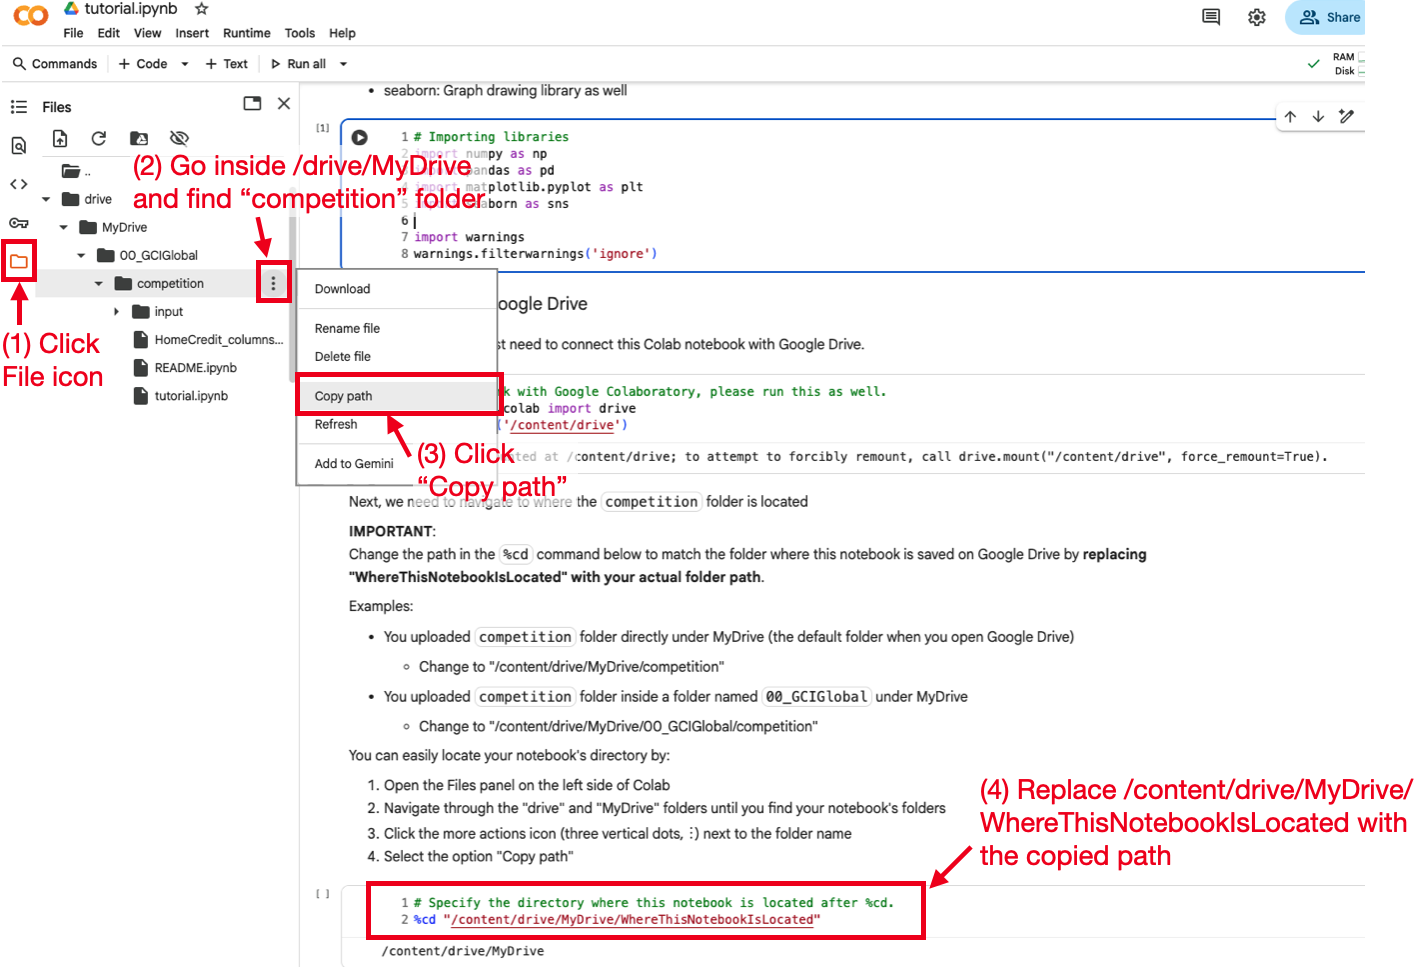

Run the cell below to check if the path is correctly set.

In [4]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [5]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3).T

train shape: (171202, 34)


,0,1,2
SK_ID_CURR,0,1,2
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Cash loans
CODE_GENDER,F,F,F
CNT_CHILDREN,0,0,0
AMT_INCOME_TOTAL,112500.0,225000.0,54000.0
AMT_CREDIT,755190.0,585000.0,334152.0
AMT_ANNUITY,36328.5,16893.0,18256.5
AMT_GOODS_PRICE,675000.0,585000.0,270000.0
NAME_INCOME_TYPE,Working,Pensioner,State servant
NAME_EDUCATION_TYPE,Higher education,Secondary / secondary special,Secondary / secondary special


In [6]:
#Changing some features to be more remenescent of actual representation

train["AGE_YEARS"]=(train["DAYS_BIRTH"]*-1)/365
test["AGE_YEARS"]=(test["DAYS_BIRTH"]*-1)/365

for df in [train, test]:
    df["DAYS_EMPLOYED_ANOMALY"] = (
        df["DAYS_EMPLOYED"] == 365243
    ).astype(int)

    df["EMPLOYED_YEARS"] = (
        -df["DAYS_EMPLOYED"] / 365
    )

    df.loc[df["DAYS_EMPLOYED"] == 365243, "EMPLOYED_YEARS"] = np.nan


train["YEARS_REGISTRATION"]=(train["DAYS_REGISTRATION"]*-1)/365
test["YEARS_REGISTRATION"]=(test["DAYS_REGISTRATION"]*-1)/365
train["YEARS_ID_PUBLISH"]=(train["DAYS_ID_PUBLISH"]*-1)/365
test["YEARS_ID_PUBLISH"]=(test["DAYS_ID_PUBLISH"]*-1)/365
train["YEARS_LAST_PHONE_CHANGE"]=(train["DAYS_LAST_PHONE_CHANGE"]*-1)/365
test["YEARS_LAST_PHONE_CHANGE"]=(test["DAYS_LAST_PHONE_CHANGE"]*-1)/365

for df in[train,test]:
  df["EXT_MEAN"]   = df[["EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]].mean(axis=1)
  df["EXT_MIN"]    = df[["EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]].min(axis=1)
  df["EXT_PROD"]   = df.EXT_SOURCE_1 * df.EXT_SOURCE_2 * df.EXT_SOURCE_3
  df["CREDIT_TERM"]        = df.AMT_ANNUITY / df.AMT_CREDIT
  df["CREDIT_GOODS_RATIO"] = df.AMT_CREDIT / df.AMT_GOODS_PRICE
  df["EMPLOYED_AGE_RATIO"] = df.EMPLOYED_YEARS / df.AGE_YEARS
  df["INCOME_PER_PERSON"]  = df.AMT_INCOME_TOTAL / df.CNT_FAM_MEMBERS

In [8]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3).T

test shape: (61500, 46)


,0,1,2
SK_ID_CURR,171202,171203,171204
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Cash loans
CODE_GENDER,F,F,F
CNT_CHILDREN,1,0,1
AMT_INCOME_TOTAL,144000.0,103500.0,180000.0
AMT_CREDIT,961146.0,296280.0,183694.5
AMT_ANNUITY,28233.0,16069.5,11236.5
AMT_GOODS_PRICE,688500.0,225000.0,139500.0
NAME_INCOME_TYPE,Working,Working,Commercial associate
NAME_EDUCATION_TYPE,Higher education,Secondary / secondary special,Secondary / secondary special


In [ ]:
train.isnull().mean()*100

,0
SK_ID_CURR,0.000000
NAME_CONTRACT_TYPE,0.000000
CODE_GENDER,0.000000
CNT_CHILDREN,0.000000
AMT_INCOME_TOTAL,0.000000
AMT_CREDIT,0.000000
AMT_ANNUITY,0.000000
AMT_GOODS_PRICE,0.000000
NAME_INCOME_TYPE,0.000000
NAME_EDUCATION_TYPE,0.000000


In [9]:
missing_indicator_cols = [
    "OWN_CAR_AGE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

for col in missing_indicator_cols:
    train[col + "_MISSING"] = train[col].isna().astype(int)
    test[col + "_MISSING"] = test[col].isna().astype(int)

In [14]:
train.isnull().mean()

,0
SK_ID_CURR,0.000000
NAME_CONTRACT_TYPE,0.000000
CODE_GENDER,0.000000
CNT_CHILDREN,0.000000
AMT_INCOME_TOTAL,0.000000
AMT_CREDIT,0.000000
AMT_ANNUITY,0.000000
AMT_GOODS_PRICE,0.000000
NAME_INCOME_TYPE,0.000000
NAME_EDUCATION_TYPE,0.000000


In [35]:
#Income per-person has na values due to being divided by zero

for d in (train, test):
    s = d["INCOME_PER_PERSON"].replace([np.inf, -np.inf], np.nan)
    d["INCOME_PER_PERSON"] = s.fillna(d["AMT_INCOME_TOTAL"])

Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

###2.1.2 Feature visualization (Mine)
Here we are about to dive into some feature visualizations. Based on these we are going to select our features.

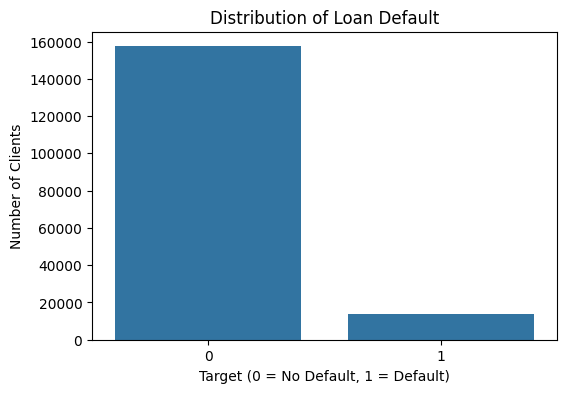

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=train, x="TARGET")

plt.title("Distribution of Loan Default")
plt.xlabel("Target (0 = No Default, 1 = Default)")
plt.ylabel("Number of Clients")

plt.show()

In [ ]:
train["TARGET"].value_counts(normalize=True)

,proportion
TARGET,
0,0.919271
1,0.080729


Here we can see that there is a class imbalance. The number of defaulters is way less than the ones who don't.

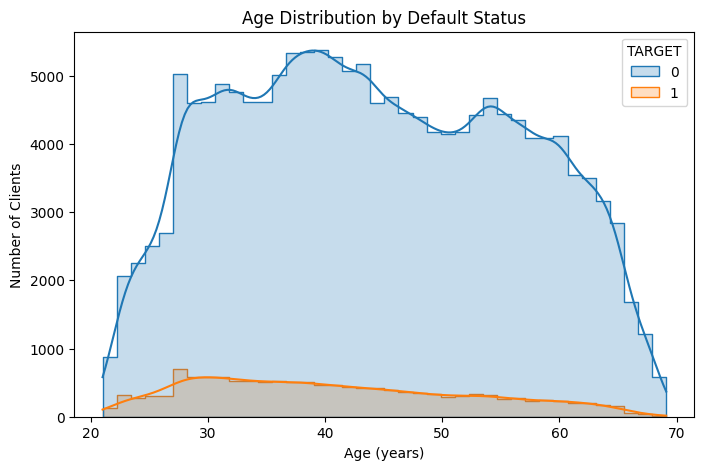

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x="AGE_YEARS",
    hue="TARGET",
    bins=40,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Age (years)")
plt.ylabel("Number of Clients")

plt.show()

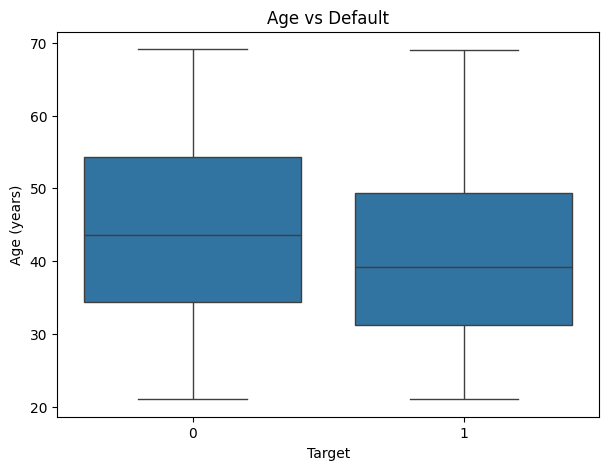

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=train,
    x="TARGET",
    y="AGE_YEARS"
)

plt.title("Age vs Default")
plt.xlabel("Target")
plt.ylabel("Age (years)")

plt.show()

The above plot is for comparing age with defaulting. We can see that the maximum amount of defaulters have an age between 30 and 50, mostly concentrated around late 30s.

In [9]:
#log based income
train["LOG_INCOME"] = np.log1p(train["AMT_INCOME_TOTAL"])

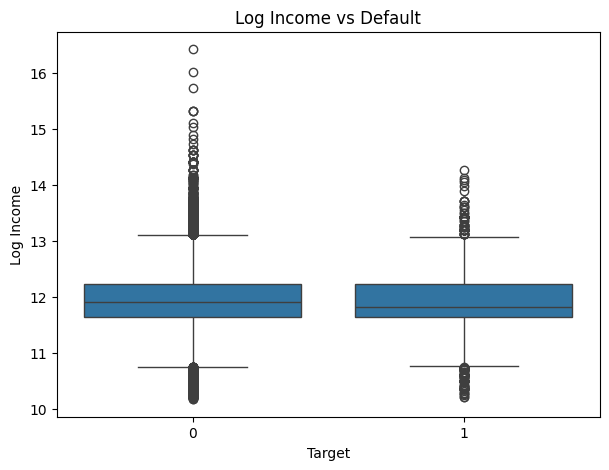

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=train,
    x="TARGET",
    y="LOG_INCOME"
)

plt.title("Log Income vs Default")
plt.xlabel("Target")
plt.ylabel("Log Income")

plt.show()

The above plots are for log income vs default types. We can see that both of them concentrate aroud the same values with non-defaulters having more outliers.


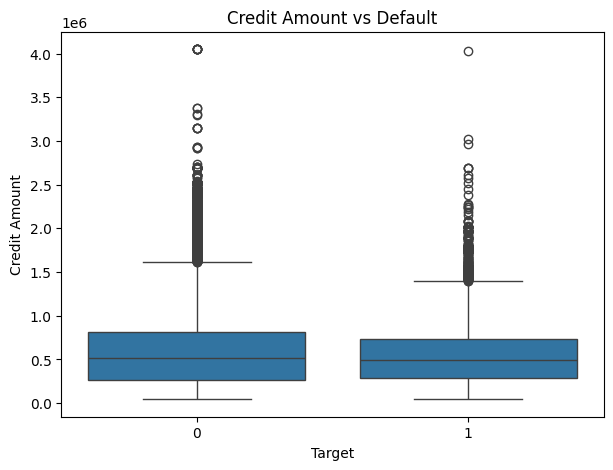

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=train,
    x="TARGET",
    y="AMT_CREDIT"
)

plt.title("Credit Amount vs Default")
plt.xlabel("Target")
plt.ylabel("Credit Amount")

plt.show()

The above plots are for credit amount vs default types. We can see that both of them concentrate aroud the same values with non-defaulters having more outliers.



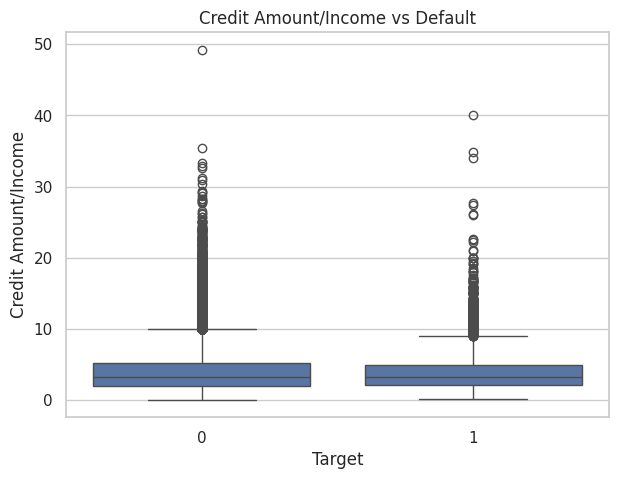

In [23]:
plt.figure(figsize=(7, 5))

train["CREDIT/INCOME"]=train["AMT_CREDIT"]/train["AMT_INCOME_TOTAL"]

sns.boxplot(
    data=train,
    x="TARGET",
    y="CREDIT/INCOME"
)

plt.title("Credit Amount/Income vs Default")
plt.xlabel("Target")
plt.ylabel("Credit Amount/Income")
plt.show()


Credit/Income is for determining how much of a burden is it for a person of a certain income to have this amount of credit.

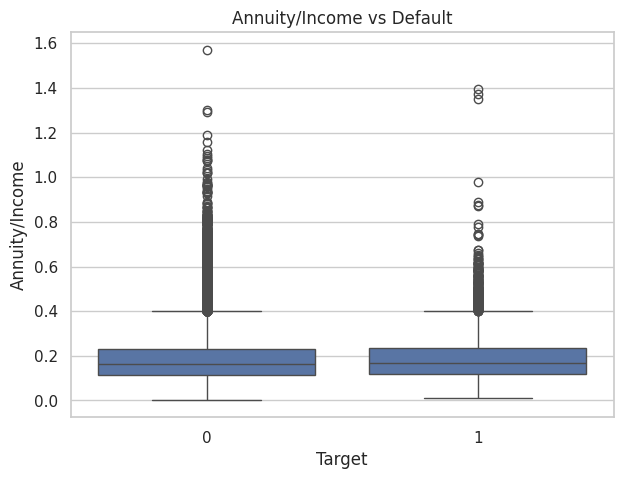

In [25]:
plt.figure(figsize=(7, 5))

train["ANNUITY/INCOME"]=train["AMT_ANNUITY"]/train["AMT_INCOME_TOTAL"]

sns.boxplot(
    data=train,
    x="TARGET",
    y="ANNUITY/INCOME"
)

plt.title("Annuity/Income vs Default")
plt.xlabel("Target")
plt.ylabel("Annuity/Income")
plt.show()


Annuity/Income is for determining how much of a burden is it for a person of a certain income to pay this amount each time.

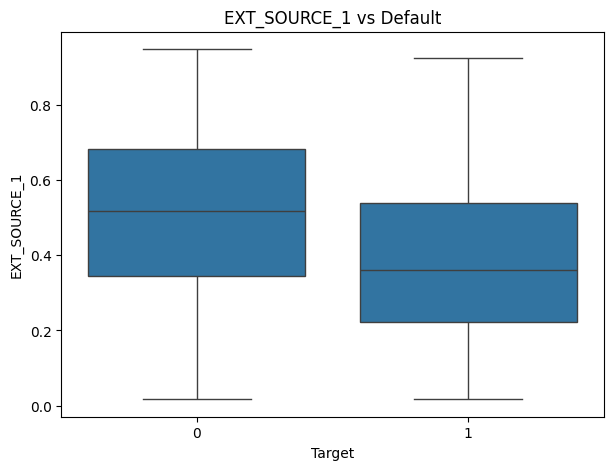

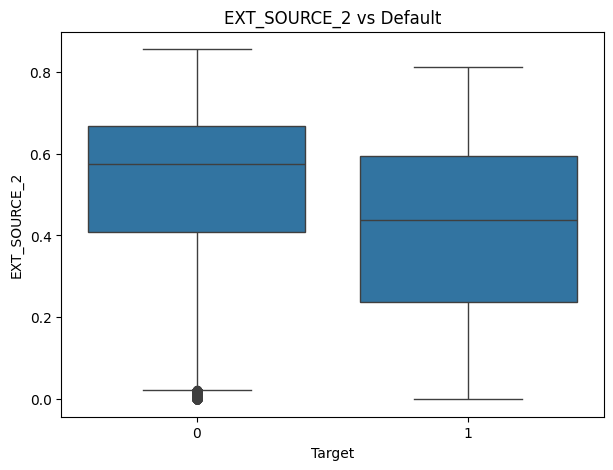

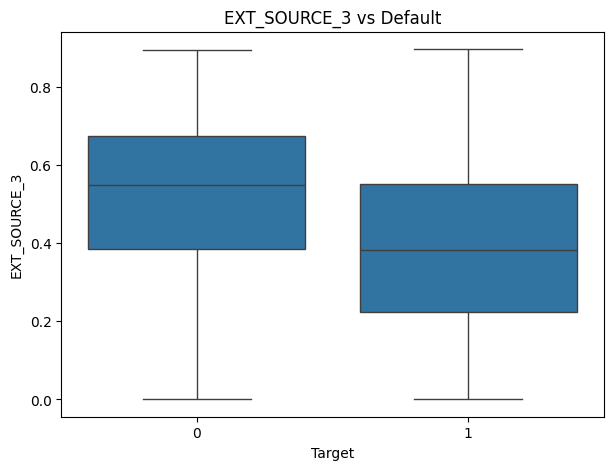

In [ ]:
for col in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=train, x="TARGET", y=col)
    plt.title(f"{col} vs Default")
    plt.xlabel("Target")
    plt.ylabel(col)
    plt.show()

These values of external validation are much more important than ever as they give higher score to non-defaulters compared to defaulters which is exactly what we want to do with our auc-roc.

In [ ]:
#For categorical data

categorical_cols = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE"
]

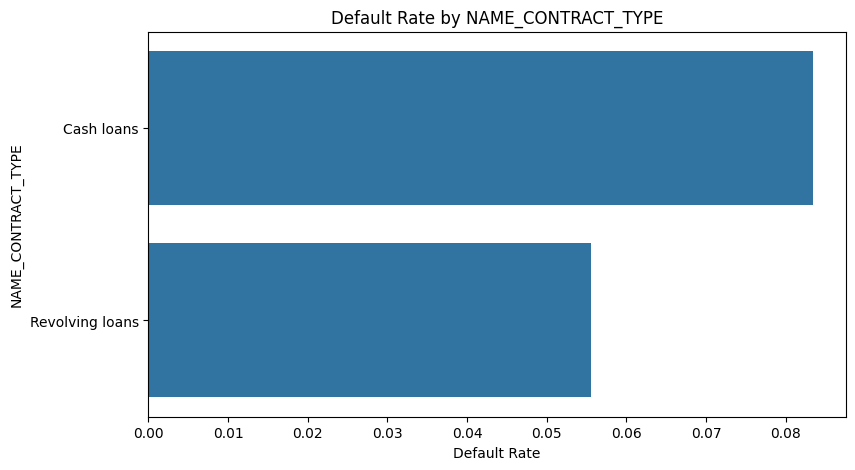

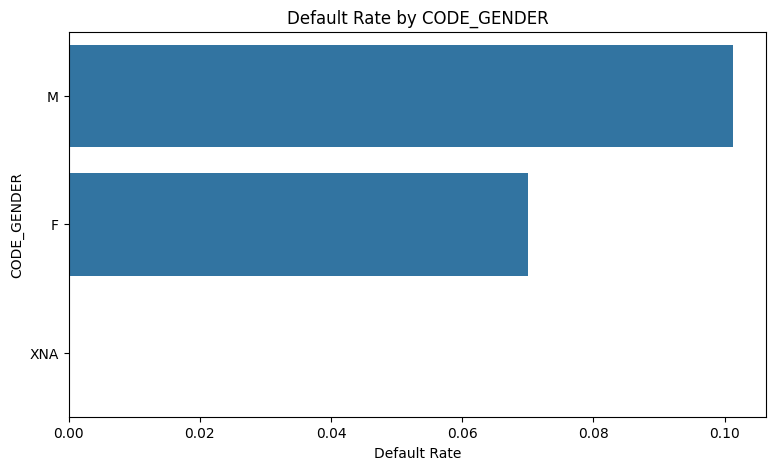

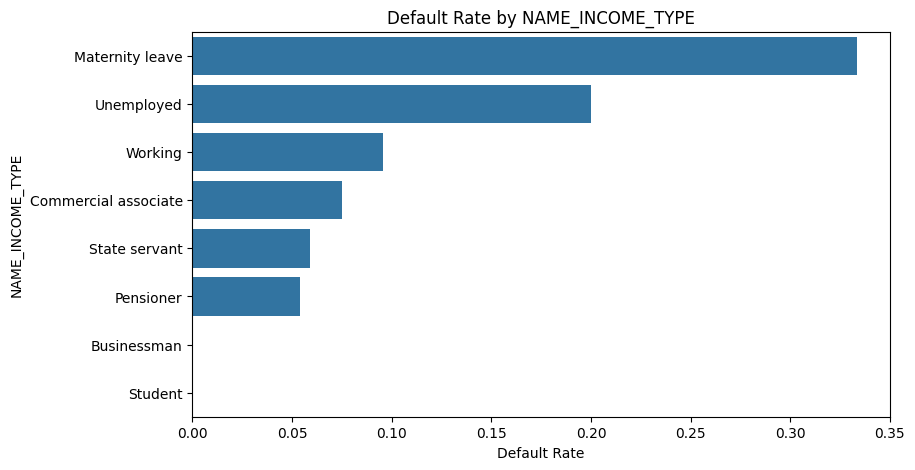

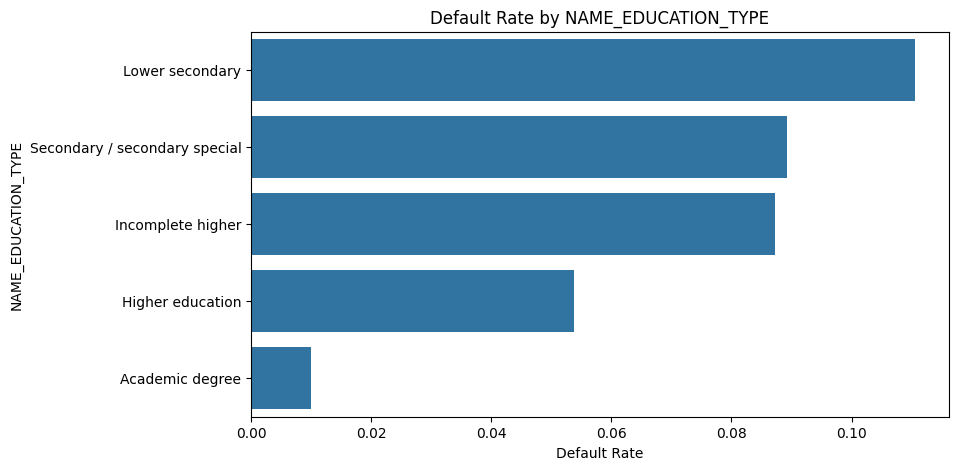

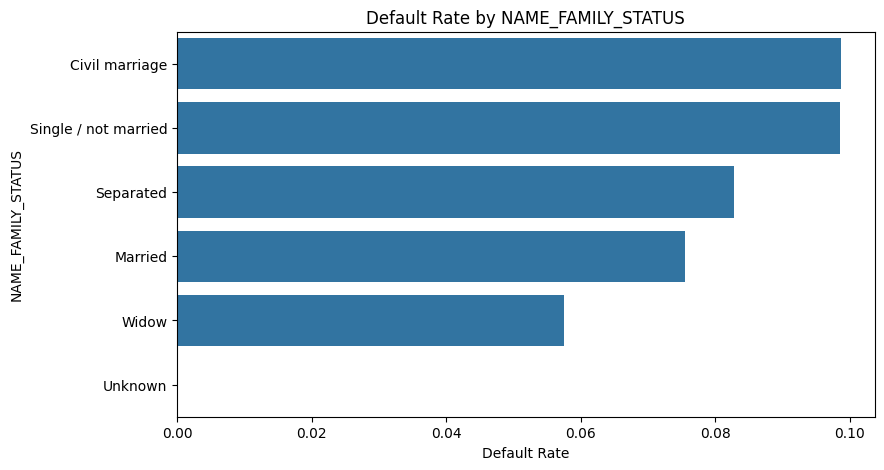

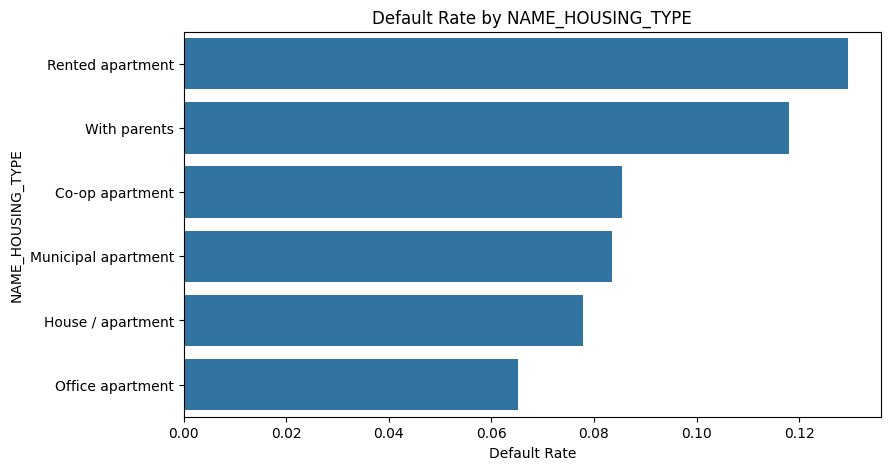

In [ ]:
for col in categorical_cols:

    default_rate = (
        train.groupby(col)["TARGET"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=default_rate.values,
        y=default_rate.index
    )

    plt.title(f"Default Rate by {col}")
    plt.xlabel("Default Rate")
    plt.ylabel(col)

    plt.show()

In [ ]:
missing_default = (
    train.groupby(train["EXT_SOURCE_1"].isna())["TARGET"]
    .mean()
)

print(missing_default)

EXT_SOURCE_1
False    0.074875
True     0.083303
Name: TARGET, dtype: float64


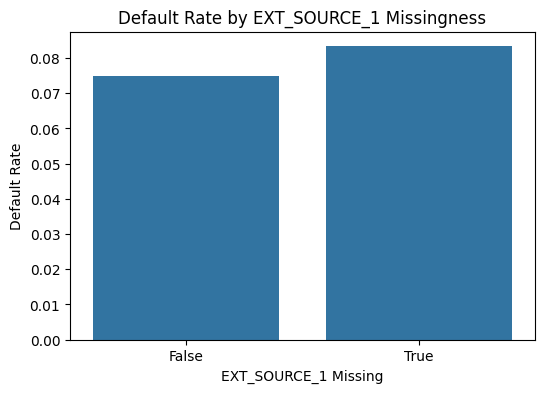

In [ ]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=missing_default.index.astype(str),
    y=missing_default.values
)

plt.title("Default Rate by EXT_SOURCE_1 Missingness")
plt.xlabel("EXT_SOURCE_1 Missing")
plt.ylabel("Default Rate")

plt.show()

In [ ]:
missing_cols = [
    "OWN_CAR_AGE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_3",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR"
]

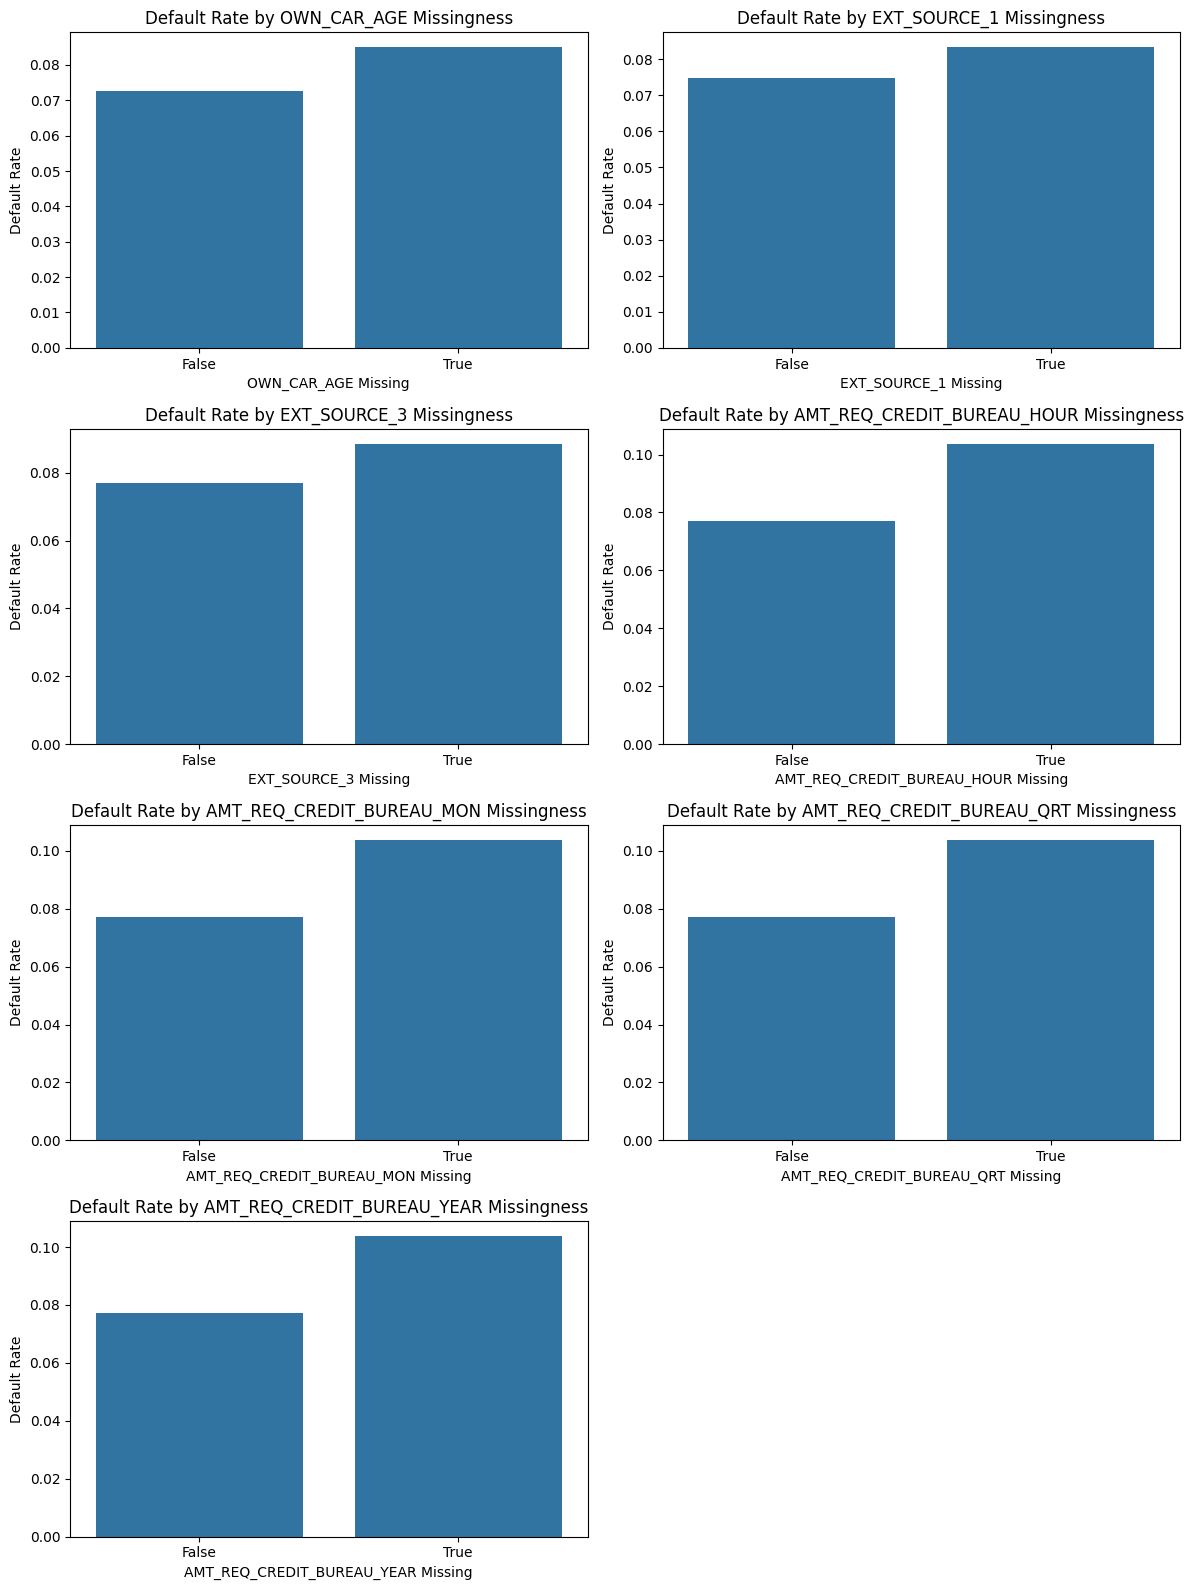

In [ ]:
# 1. Initialize the grid ONCE outside the loop (4 rows, 2 columns = 8 subplots)
fig, axe = plt.subplots(4, 2, figsize=(12, 16))  # Increased height to 16 for 4 rows
axes = axe.flatten()  # Flatten to a 1D array of 8 elements

# 2. Loop through columns with an index counter
for idx, col in enumerate(missing_cols):
    # If you have more columns than grid spots, stop to prevent an IndexError
    if idx >= len(axes):
        break

    missing_default = train.groupby(train[col].isna())["TARGET"].mean()

    # 3. Pass the specific axis to Seaborn using axes[idx]
    sns.barplot(
        x=missing_default.index.astype(str),
        y=missing_default.values,
        ax=axes[idx]  # <-- CRITICAL: Tells Seaborn where to draw
    )

    # 4. Apply labels directly to the specific axis
    axes[idx].set_title(f"Default Rate by {col} Missingness")
    axes[idx].set_xlabel(f"{col} Missing")
    axes[idx].set_ylabel("Default Rate")

# 5. Hide any unused empty subplots if missing_cols has fewer than 8 items
for empty_ax in axes[len(missing_cols):]:
    empty_ax.set_visible(False)

# 6. Adjust layout and show the single comprehensive window
plt.tight_layout()
plt.show()

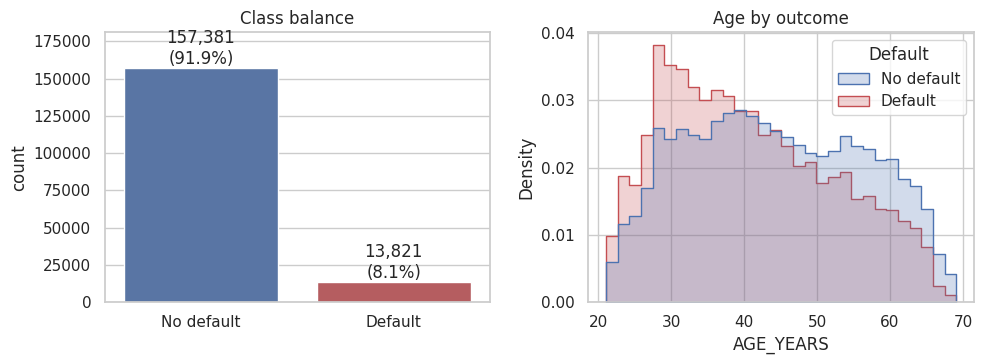

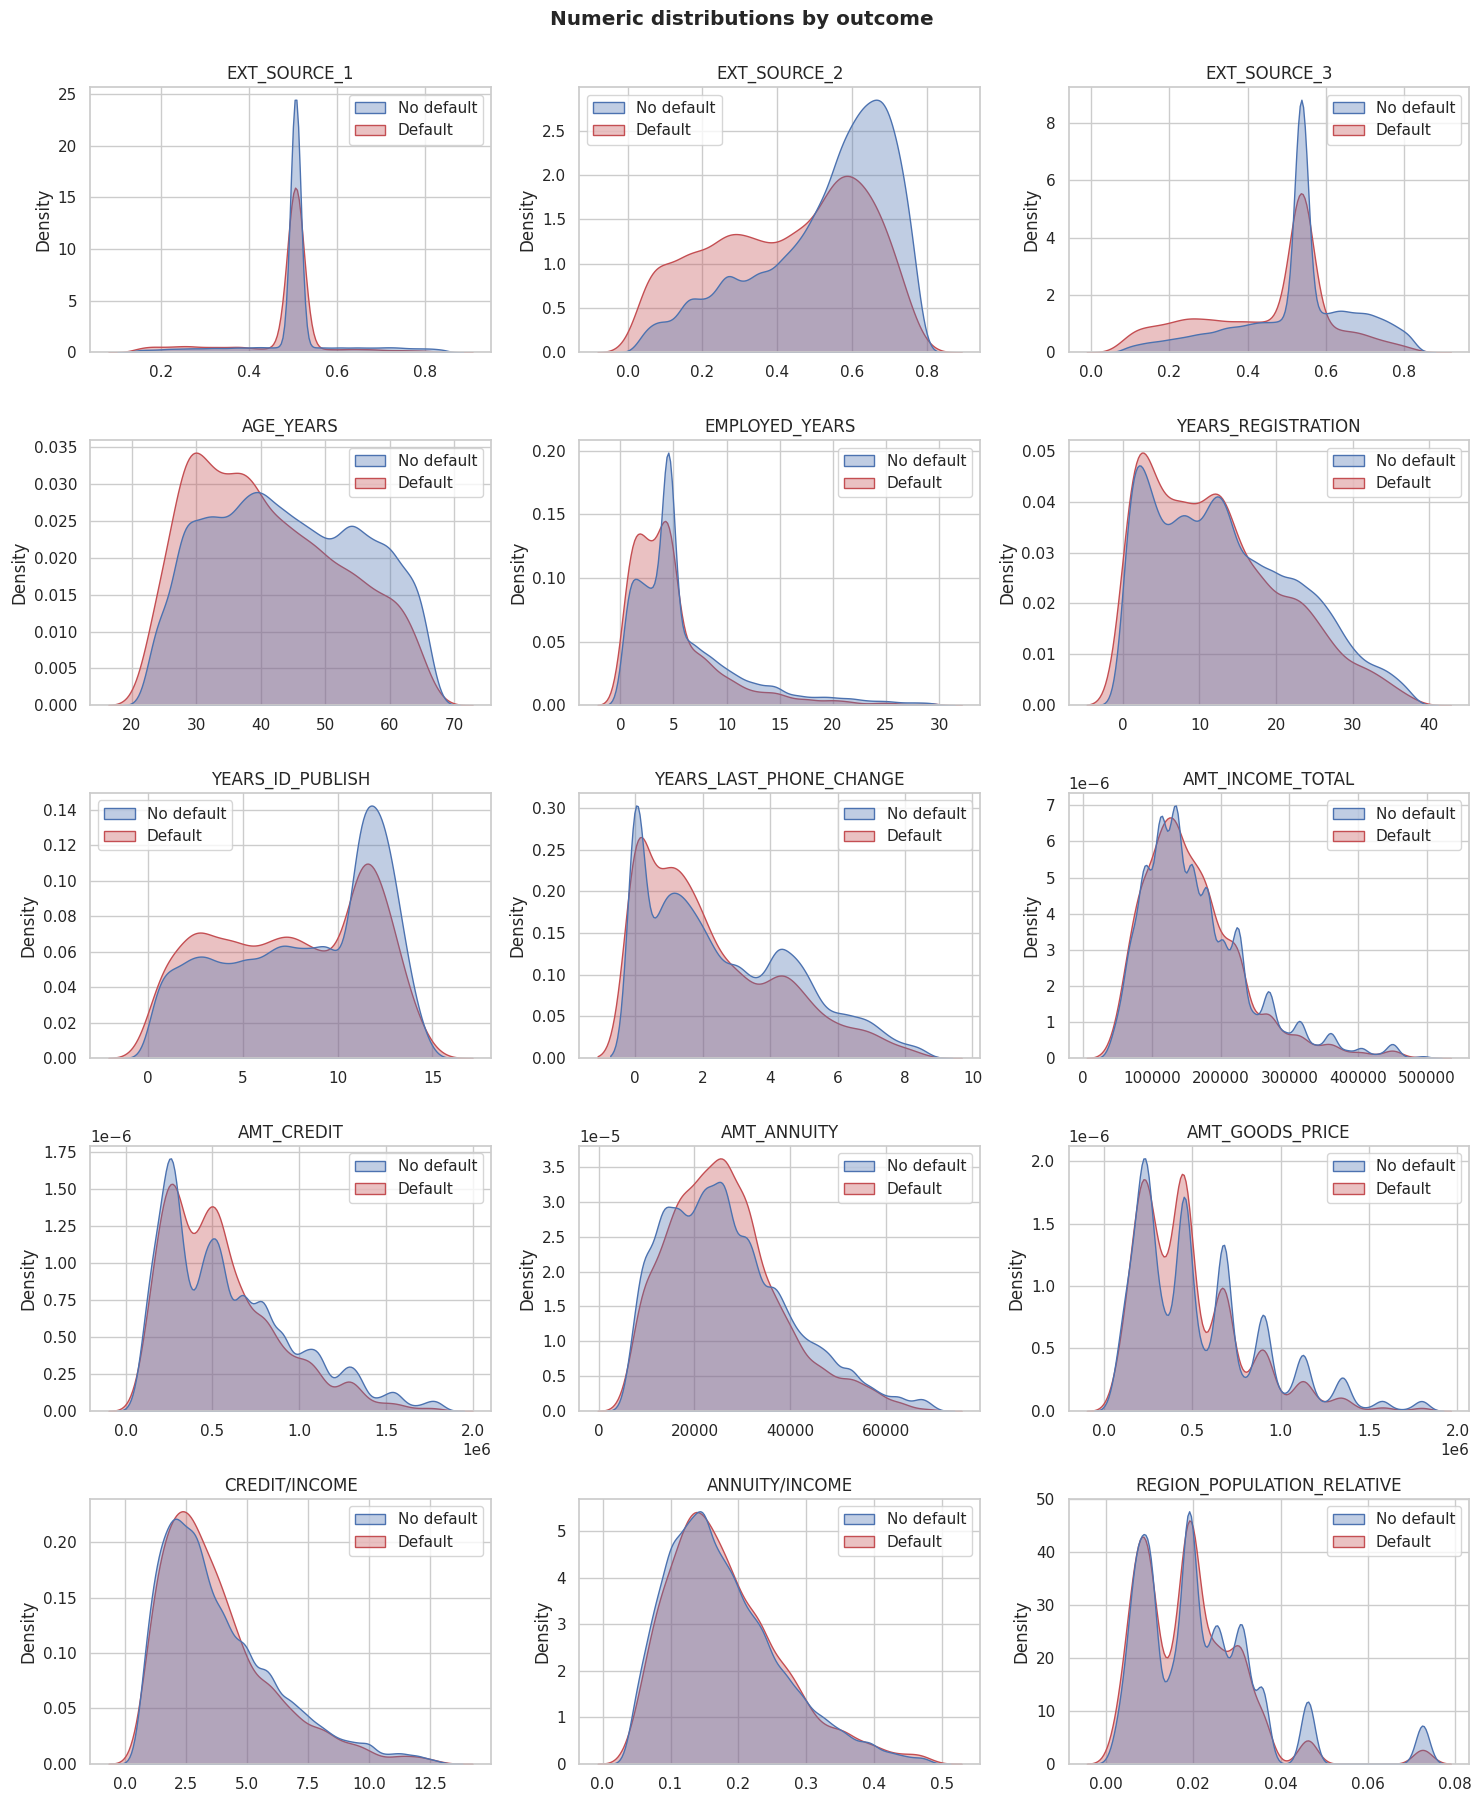

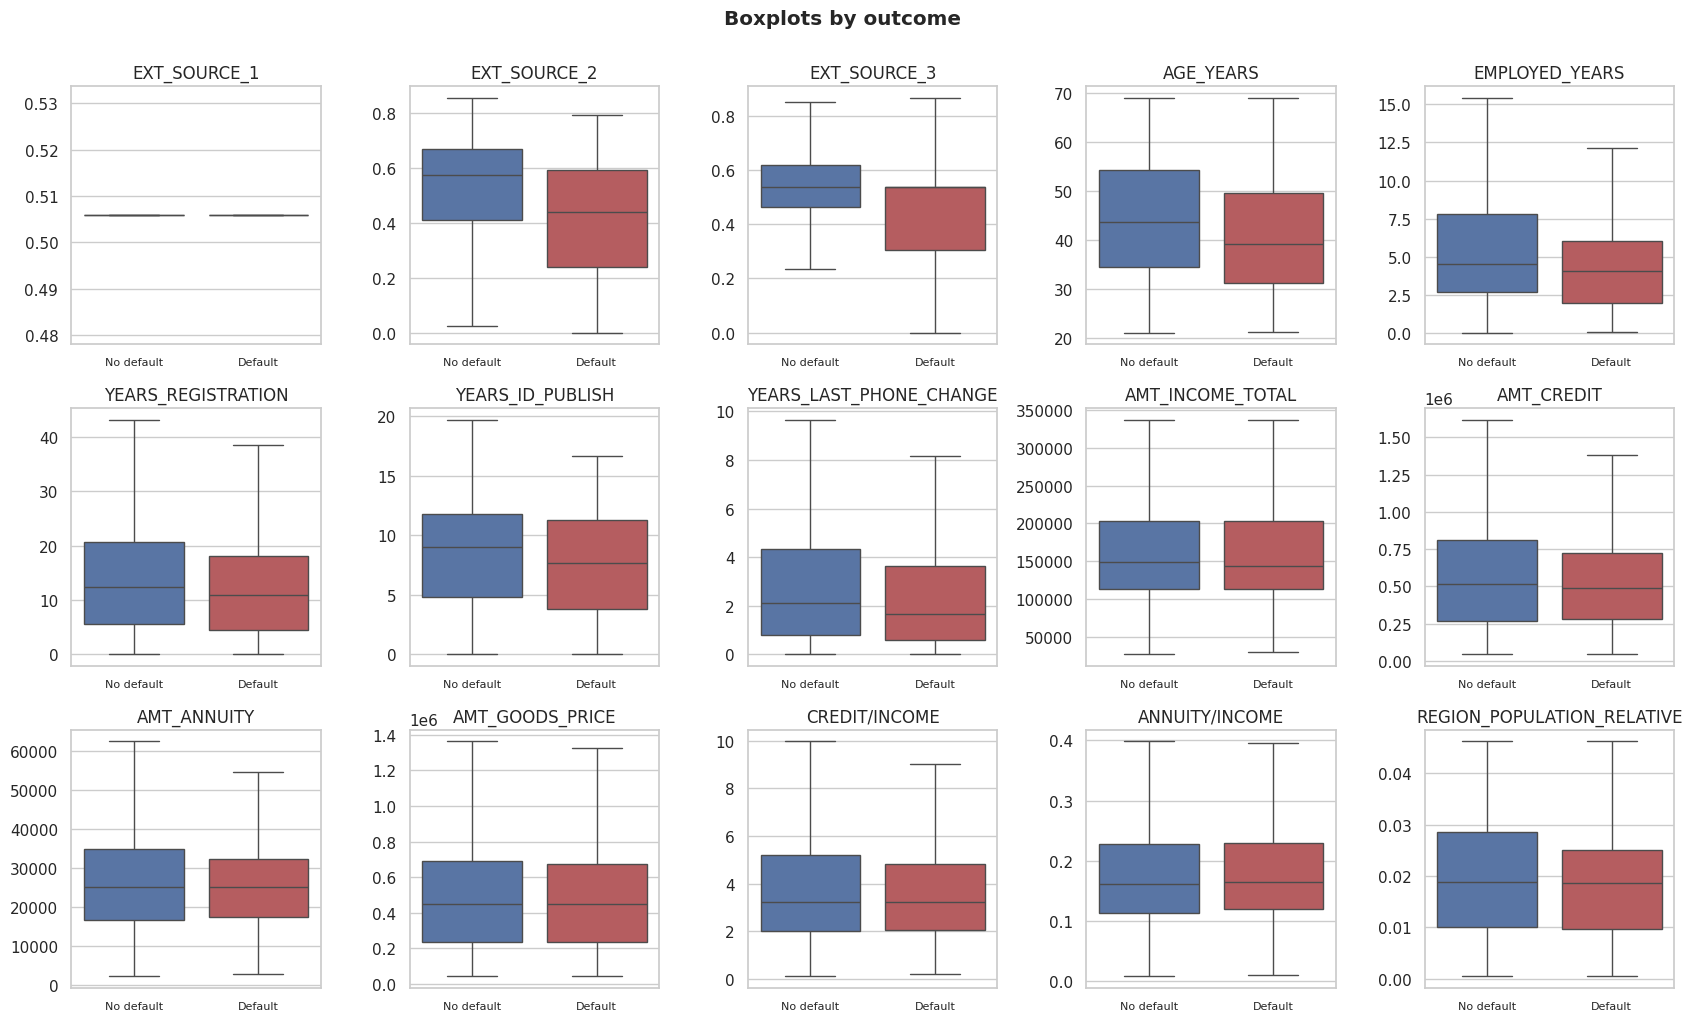

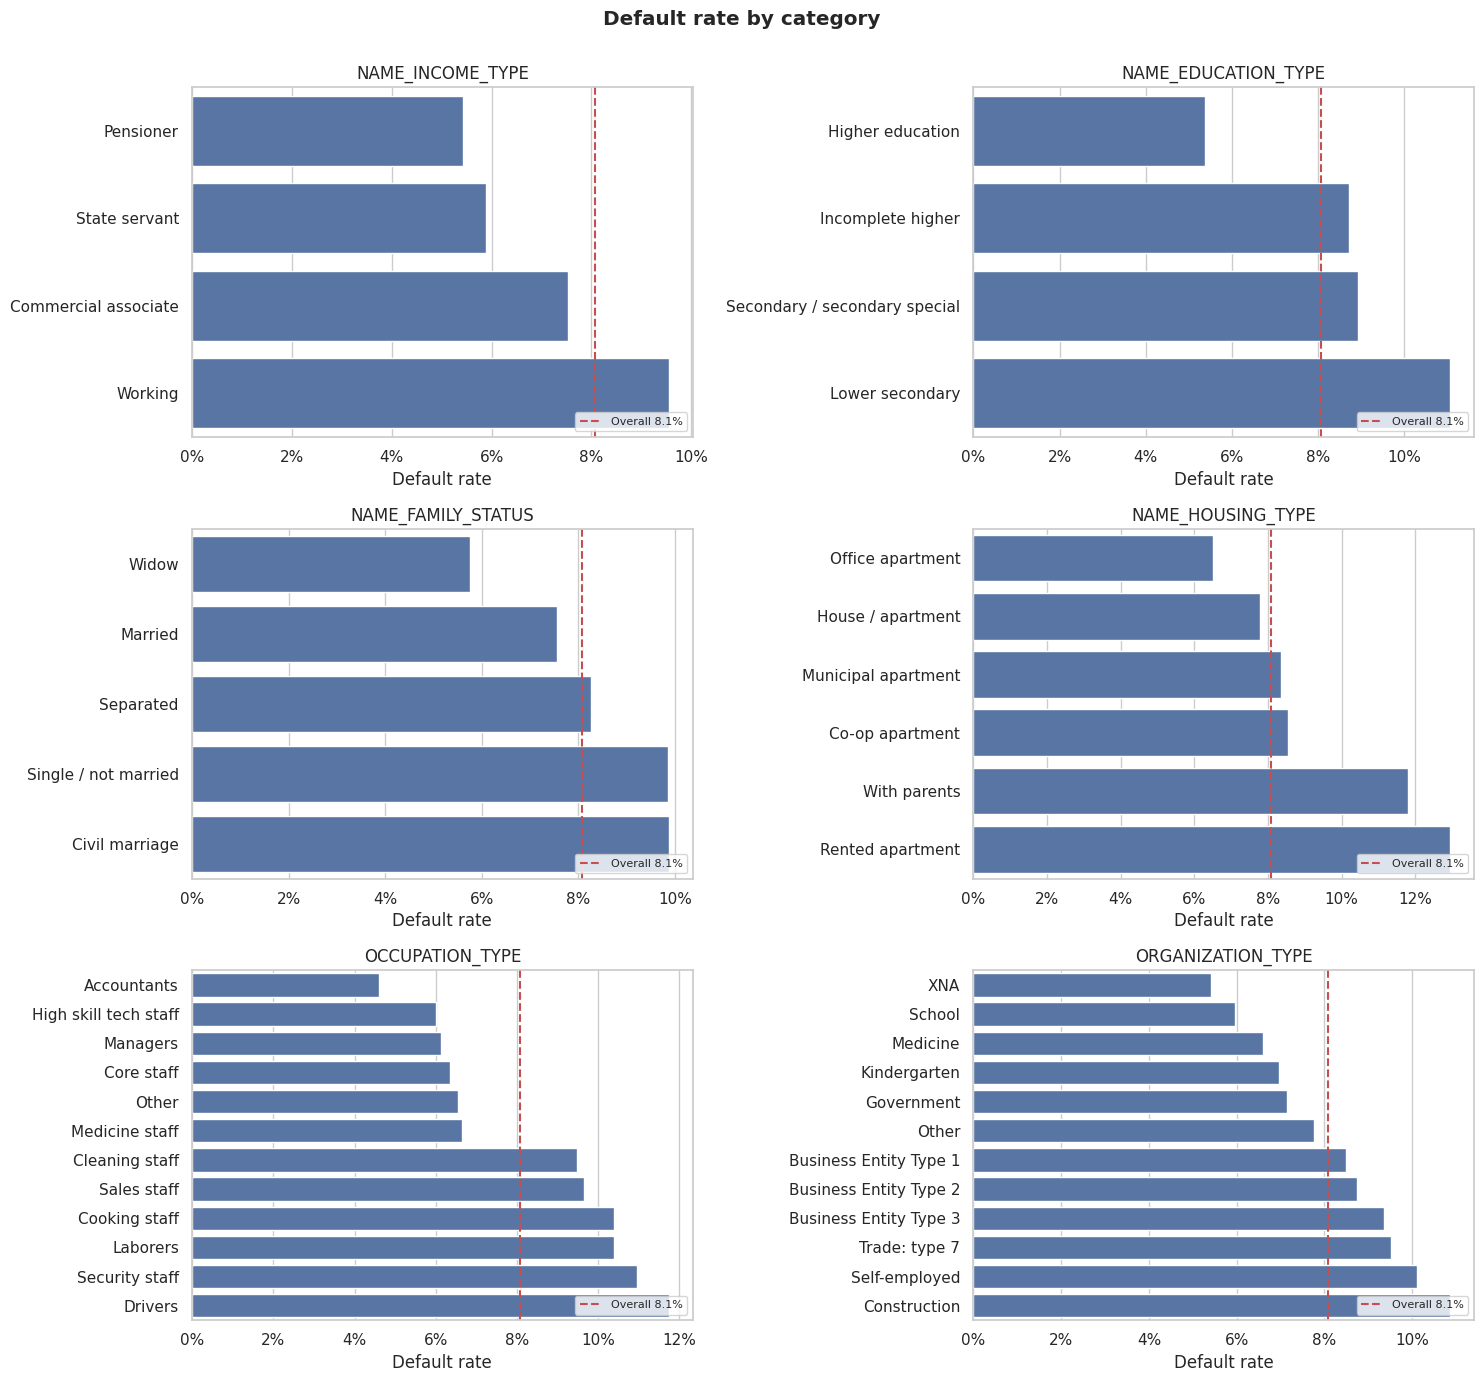

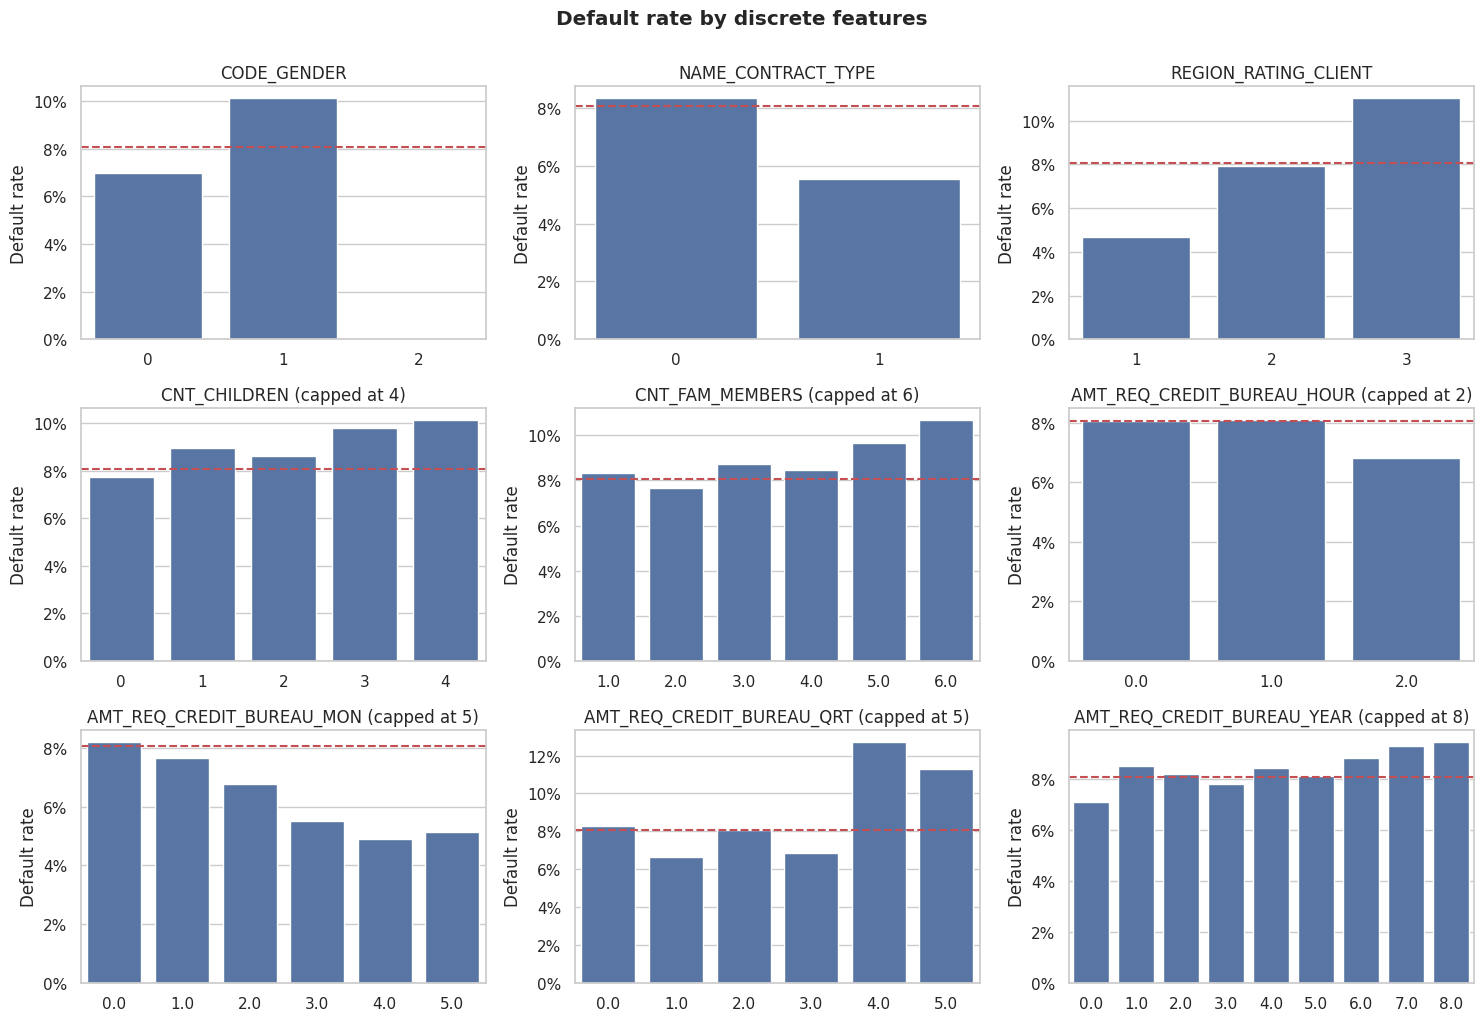

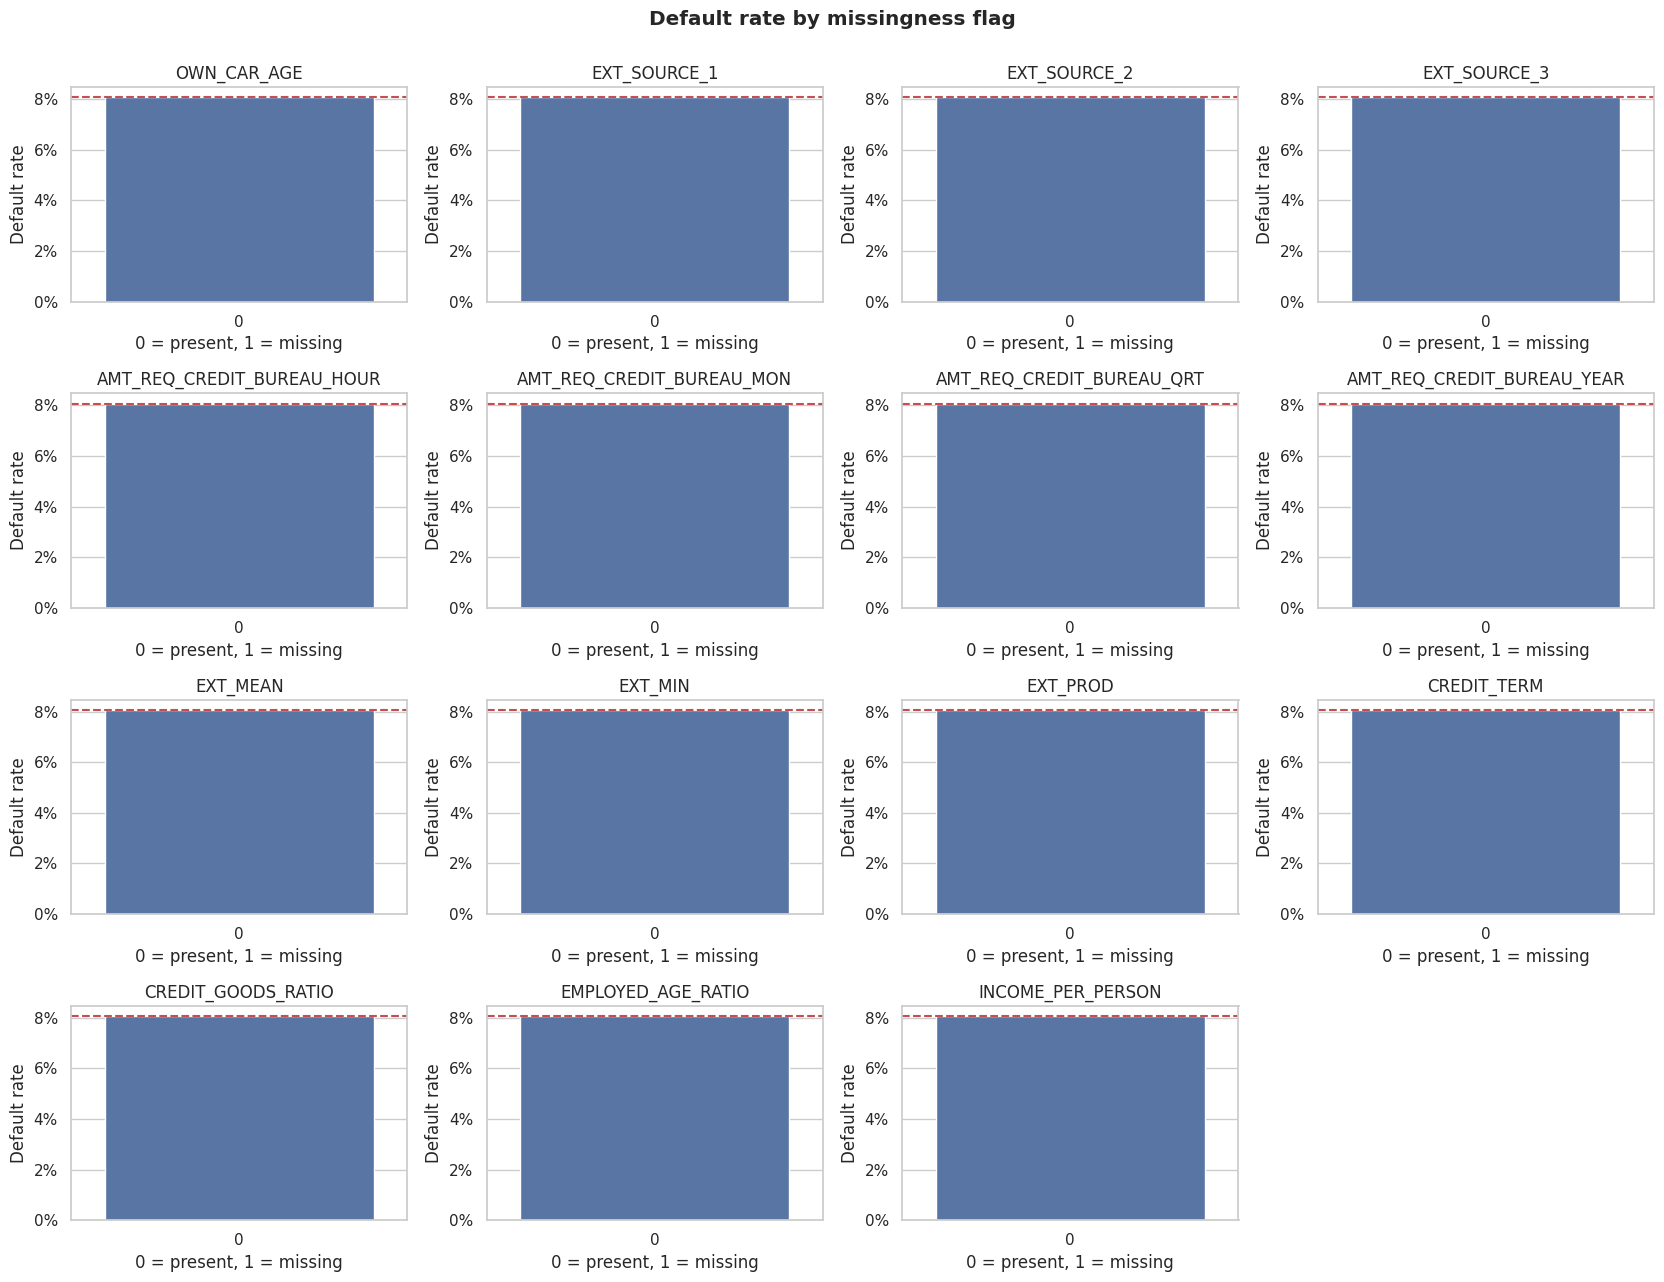

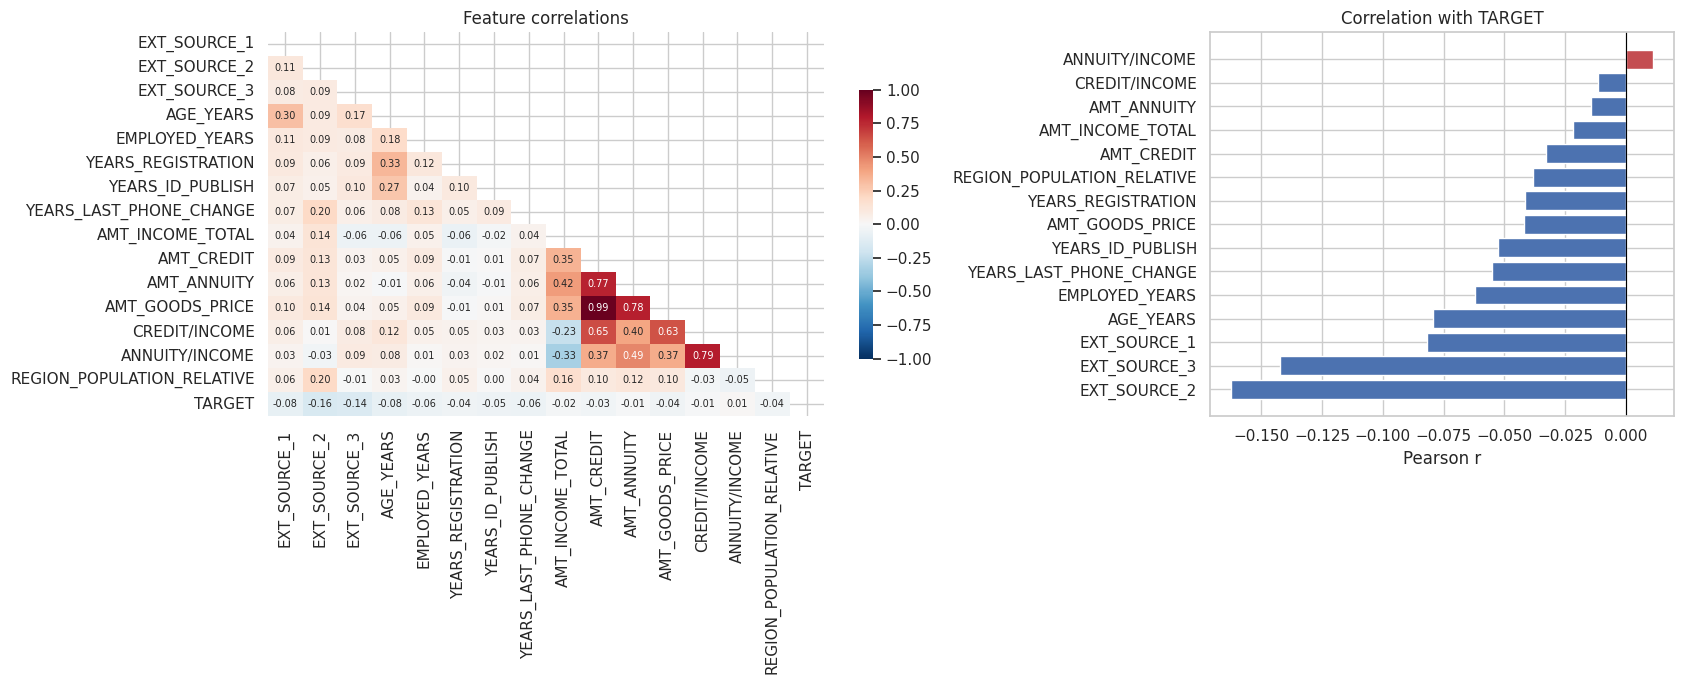

In [55]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PAL = {"No default": "#4C72B0", "Default": "#C44E52"}
d = train.copy()
d["Default"] = d["TARGET"].map({0: "No default", 1: "Default"})
overall = train["TARGET"].mean()
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

df=train.copy()

def grid(n, ncols, w, h):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes

num_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "EMPLOYED_YEARS",
            "YEARS_REGISTRATION", "YEARS_ID_PUBLISH", "YEARS_LAST_PHONE_CHANGE",
            "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
            "CREDIT/INCOME", "ANNUITY/INCOME", "REGION_POPULATION_RELATIVE"]
cat_cols = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
            "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
ord_cols = {"CODE_GENDER": None, "NAME_CONTRACT_TYPE": None, "REGION_RATING_CLIENT": None,
            "CNT_CHILDREN": 4, "CNT_FAM_MEMBERS": 6, "AMT_REQ_CREDIT_BUREAU_HOUR": 2,
            "AMT_REQ_CREDIT_BUREAU_MON": 5, "AMT_REQ_CREDIT_BUREAU_QRT": 5,
            "AMT_REQ_CREDIT_BUREAU_YEAR": 8}
miss_cols = [c for c in df.columns if c.endswith("_MISSING")]

# 1) Target balance + age
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.countplot(data=d, x="Default", order=list(PAL), hue="Default", palette=PAL, legend=False, ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(d):.1%})",
                   (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[0].set(title="Class balance", xlabel=""); ax[0].margins(y=0.15)
sns.histplot(data=d, x="AGE_YEARS", hue="Default", palette=PAL, stat="density",
             common_norm=False, element="step", bins=30, ax=ax[1])
ax[1].set_title("Age by outcome")
plt.tight_layout(); plt.show()

# 2) Numeric KDEs by outcome (1st-99th percentile, 60k sample for speed)
s = d.sample(min(len(d), 60_000), random_state=42)
fig, axes = grid(len(num_cols), 3, 5, 3.6)
for ax, c in zip(axes, num_cols):
    lo, hi = s[c].quantile([0.01, 0.99])
    sns.kdeplot(data=s[s[c].between(lo, hi)], x=c, hue="Default", palette=PAL,
                common_norm=False, fill=True, alpha=0.35, ax=ax, warn_singular=False)
    ax.set(title=c, xlabel="")
    if ax.get_legend(): ax.get_legend().set_title("")
fig.suptitle("Numeric distributions by outcome", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# 3) Numeric boxplots by outcome
fig, axes = grid(len(num_cols), 5, 3.4, 3.4)
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=s, x="Default", y=c, order=list(PAL), hue="Default", palette=PAL,
                legend=False, showfliers=False, ax=ax)
    ax.set(title=c, xlabel="", ylabel="")
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Boxplots by outcome", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# 4) Default rate by category (12 most frequent levels, sorted by rate)
fig, axes = grid(len(cat_cols), 2, 7.5, 4.6)
for ax, c in zip(axes, cat_cols):
    st = df.groupby(c, observed=True)["TARGET"].agg(rate="mean", n="size").reset_index()
    st = st[st.n >= 200].nlargest(12, "n").sort_values("rate")
    sns.barplot(data=st, x="rate", y=c, color="#4C72B0", ax=ax)
    ax.axvline(overall, color="#C44E52", ls="--", label=f"Overall {overall:.1%}")
    ax.set(title=c, xlabel="Default rate", ylabel=""); ax.xaxis.set_major_formatter(pct)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Default rate by category", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# 5) Default rate for discrete / count features
fig, axes = grid(len(ord_cols), 3, 5, 3.4)
for ax, (c, cap) in zip(axes, ord_cols.items()):
    x = df[c] if cap is None else df[c].clip(upper=cap)
    sns.barplot(x=x, y=df["TARGET"], errorbar=None, color="#4C72B0", ax=ax)
    ax.axhline(overall, color="#C44E52", ls="--")
    ax.set(title=c if cap is None else f"{c} (capped at {cap})", xlabel="", ylabel="Default rate")
    ax.yaxis.set_major_formatter(pct)
fig.suptitle("Default rate by discrete features", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# 6) Is missingness predictive?
fig, axes = grid(len(miss_cols), 4, 4.2, 3.2)
for ax, c in zip(axes, miss_cols):
    sns.barplot(x=df[c], y=df["TARGET"], errorbar=None, hue=df[c],
                palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.axhline(overall, color="#C44E52", ls="--")
    ax.set(title=c.replace("_MISSING", ""), xlabel="0 = present, 1 = missing", ylabel="Default rate")
    ax.yaxis.set_major_formatter(pct)
fig.suptitle("Default rate by missingness flag", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

# 7) Correlations
corr = df[num_cols + ["TARGET"]].corr()
tc = corr["TARGET"].drop("TARGET").sort_values()
fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7}, ax=ax[0])
ax[0].set_title("Feature correlations")
ax[1].barh(tc.index, tc.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in tc.values])
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set(title="Correlation with TARGET", xlabel="Pearson r")
plt.tight_layout(); plt.show()

###2.1.3 Filling in the missing values
We are going to fill in the missing data.

In [37]:
missing_cols = [
    "OWN_CAR_AGE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "EXT_MEAN" ,
    "EXT_MIN" ,
    "EXT_PROD",
    "CREDIT_TERM" ,
    "CREDIT_GOODS_RATIO",
    "EMPLOYED_AGE_RATIO" ,
    "INCOME_PER_PERSON"

]

for col in missing_cols:
    train[col + "_MISSING"] = train[col].isna().astype(int)
    test[col + "_MISSING"] = test[col].isna().astype(int)

In [38]:
#test doesnt have some columns, so adding them

test["CREDIT/INCOME"]=test["AMT_CREDIT"]/test["AMT_INCOME_TOTAL"]
test["ANNUITY/INCOME"]=test["AMT_ANNUITY"]/test["AMT_INCOME_TOTAL"]
test["LOG_INCOME"]=np.log1p(test["AMT_INCOME_TOTAL"])

In [39]:
#Filling up with median
numeric_cols = train.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if col == "TARGET":
        continue

    median = train[col].median()

    train[col] = train[col].fillna(median)
    test[col] = test[col].fillna(median)

###2.1.4 Encoding the values for categorical values(Mine)


In [30]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train["CODE_GENDER"].replace({'F': 0, 'M': 1,'XNA':2}, inplace=True)
test["CODE_GENDER"].replace({'F': 0, 'M': 1}, inplace=True)


train.head(1).T

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,112500.0
...,...
CREDIT_GOODS_RATIO_MISSING,0
EMPLOYED_AGE_RATIO_MISSING,0
INCOME_PER_PERSON_MISSING,0
CREDIT/INCOME,6.7128


### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [ ]:
# Focus on 5 features
use_features = [
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_2",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    # add new features to use here
]
target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

###2.2.1 Selecting features (Mine)
We are going to select a model based on our discovered features

In [62]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 64 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   SK_ID_CURR                          171202 non-null  int64  
 1   NAME_CONTRACT_TYPE                  171202 non-null  int64  
 2   CODE_GENDER                         171202 non-null  int64  
 3   CNT_CHILDREN                        171202 non-null  int64  
 4   AMT_INCOME_TOTAL                    171202 non-null  float64
 5   AMT_CREDIT                          171202 non-null  float64
 6   AMT_ANNUITY                         171202 non-null  float64
 7   AMT_GOODS_PRICE                     171202 non-null  float64
 8   NAME_INCOME_TYPE                    171202 non-null  object 
 9   NAME_EDUCATION_TYPE                 171202 non-null  object 
 10  NAME_FAMILY_STATUS                  171202 non-null  object 
 11  NAME_HOUSING_TYPE         

In [59]:
cat_cols = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE"
]

feature_cols = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "NAME_INCOME_TYPE",
    "AMT_INCOME_TOTAL",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "REGION_POPULATION_RELATIVE",
    "FLAG_EMP_PHONE",
    "FLAG_WORK_PHONE",
    "OCCUPATION_TYPE",
    "REGION_RATING_CLIENT",
    "ORGANIZATION_TYPE",
    "EXT_SOURCE_1",
    "DAYS_LAST_PHONE_CHANGE",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "OWN_CAR_AGE_MISSING",
    "AMT_GOODS_PRICE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    # engineered
    "AGE_YEARS",
    "EMPLOYED_YEARS",
    "DAYS_EMPLOYED_ANOMALY",
    "YEARS_LAST_PHONE_CHANGE",

    # missingness indicators
    "EXT_SOURCE_1_MISSING",
    "EXT_SOURCE_3_MISSING",
    "AMT_REQ_CREDIT_BUREAU_HOUR_MISSING",
    "AMT_REQ_CREDIT_BUREAU_MON_MISSING",
    "AMT_REQ_CREDIT_BUREAU_QRT_MISSING",
    "AMT_REQ_CREDIT_BUREAU_YEAR_MISSING",

    # engineered financial
    "CREDIT/INCOME",
    "ANNUITY/INCOME",
    "EXT_MEAN",
    "EXT_MIN",
    "EXT_PROD",
    "CREDIT_TERM",
    "EMPLOYED_AGE_RATIO"
]

#Our target
target="TARGET"


In [67]:
use_features = [
    # contract / client basics
    "NAME_CONTRACT_TYPE", "CODE_GENDER", "CNT_CHILDREN", "CNT_FAM_MEMBERS",

    # amounts
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",

    # categorical (strings)
    "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE",

    # region / flags
    "REGION_POPULATION_RELATIVE", "REGION_RATING_CLIENT",
    "FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE",

    # raw day counts + car
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE", "OWN_CAR_AGE",

    # external scores
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",

    # credit bureau enquiries
    "AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",

    # engineered: time-based
    "AGE_YEARS", "DAYS_EMPLOYED_ANOMALY", "EMPLOYED_YEARS",
    "YEARS_REGISTRATION", "YEARS_ID_PUBLISH", "YEARS_LAST_PHONE_CHANGE",

    # engineered: ratios / aggregates
    "EXT_MEAN", "EXT_MIN", "EXT_PROD", "CREDIT_TERM", "CREDIT_GOODS_RATIO",
    "EMPLOYED_AGE_RATIO", "INCOME_PER_PERSON", "CREDIT/INCOME", "ANNUITY/INCOME",

    # missingness flags
    "OWN_CAR_AGE_MISSING", "EXT_SOURCE_1_MISSING", "EXT_SOURCE_2_MISSING",
    "EXT_SOURCE_3_MISSING", "AMT_REQ_CREDIT_BUREAU_HOUR_MISSING",
    "AMT_REQ_CREDIT_BUREAU_MON_MISSING", "AMT_REQ_CREDIT_BUREAU_QRT_MISSING",
    "AMT_REQ_CREDIT_BUREAU_YEAR_MISSING", "EXT_MEAN_MISSING", "EXT_MIN_MISSING",
    "EXT_PROD_MISSING", "CREDIT_TERM_MISSING", "CREDIT_GOODS_RATIO_MISSING",
    "EMPLOYED_AGE_RATIO_MISSING", "INCOME_PER_PERSON_MISSING",
]

cat_cols = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS",
            "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
target = "TARGET"

feature_cols = use_features   # so the later cells keep working

In [32]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 64 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   SK_ID_CURR                          171202 non-null  int64  
 1   NAME_CONTRACT_TYPE                  171202 non-null  int64  
 2   CODE_GENDER                         171202 non-null  int64  
 3   CNT_CHILDREN                        171202 non-null  int64  
 4   AMT_INCOME_TOTAL                    171202 non-null  float64
 5   AMT_CREDIT                          171202 non-null  float64
 6   AMT_ANNUITY                         171202 non-null  float64
 7   AMT_GOODS_PRICE                     171202 non-null  float64
 8   NAME_INCOME_TYPE                    171202 non-null  object 
 9   NAME_EDUCATION_TYPE                 171202 non-null  object 
 10  NAME_FAMILY_STATUS                  171202 non-null  object 
 11  NAME_HOUSING_TYPE         

Let's check the data once again.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 6)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,Cash loans,112500.0,0.372591,NaN,School,0
1,Cash loans,225000.0,0.449567,NaN,XNA,0
2,Cash loans,54000.0,0.569503,NaN,Postal,0


In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 5)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE
0,Cash loans,144000.0,0.720416,NaN,Kindergarten
1,Cash loans,103500.0,0.287306,NaN,School
2,Cash loans,180000.0,0.352456,NaN,Trade: type 7


### **[Next Steps]**
> + Try adding more features, starting with the ones that you think are more relevant for predicting default probability. Check `HomeCredit_columns_description.xlsx` to understand what each column represents.
> + When you add new features, always restart from [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [ ]:
# Check missing values of train data
train.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,369
OWN_CAR_AGE,112992
ORGANIZATION_TYPE,0
TARGET,0


In [ ]:
# Check missing values of test data
test.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,130
OWN_CAR_AGE,40909
ORGANIZATION_TYPE,0


We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

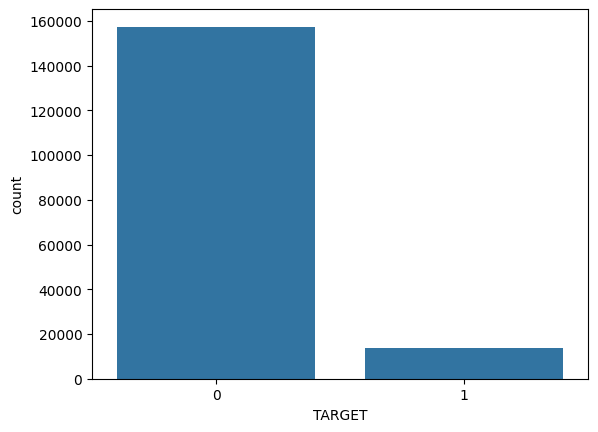

In [ ]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

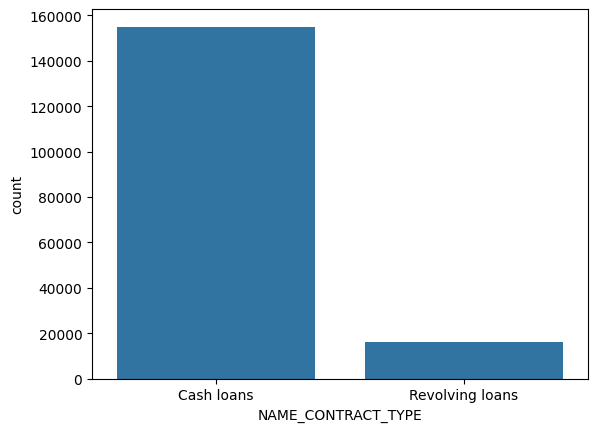

In [ ]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

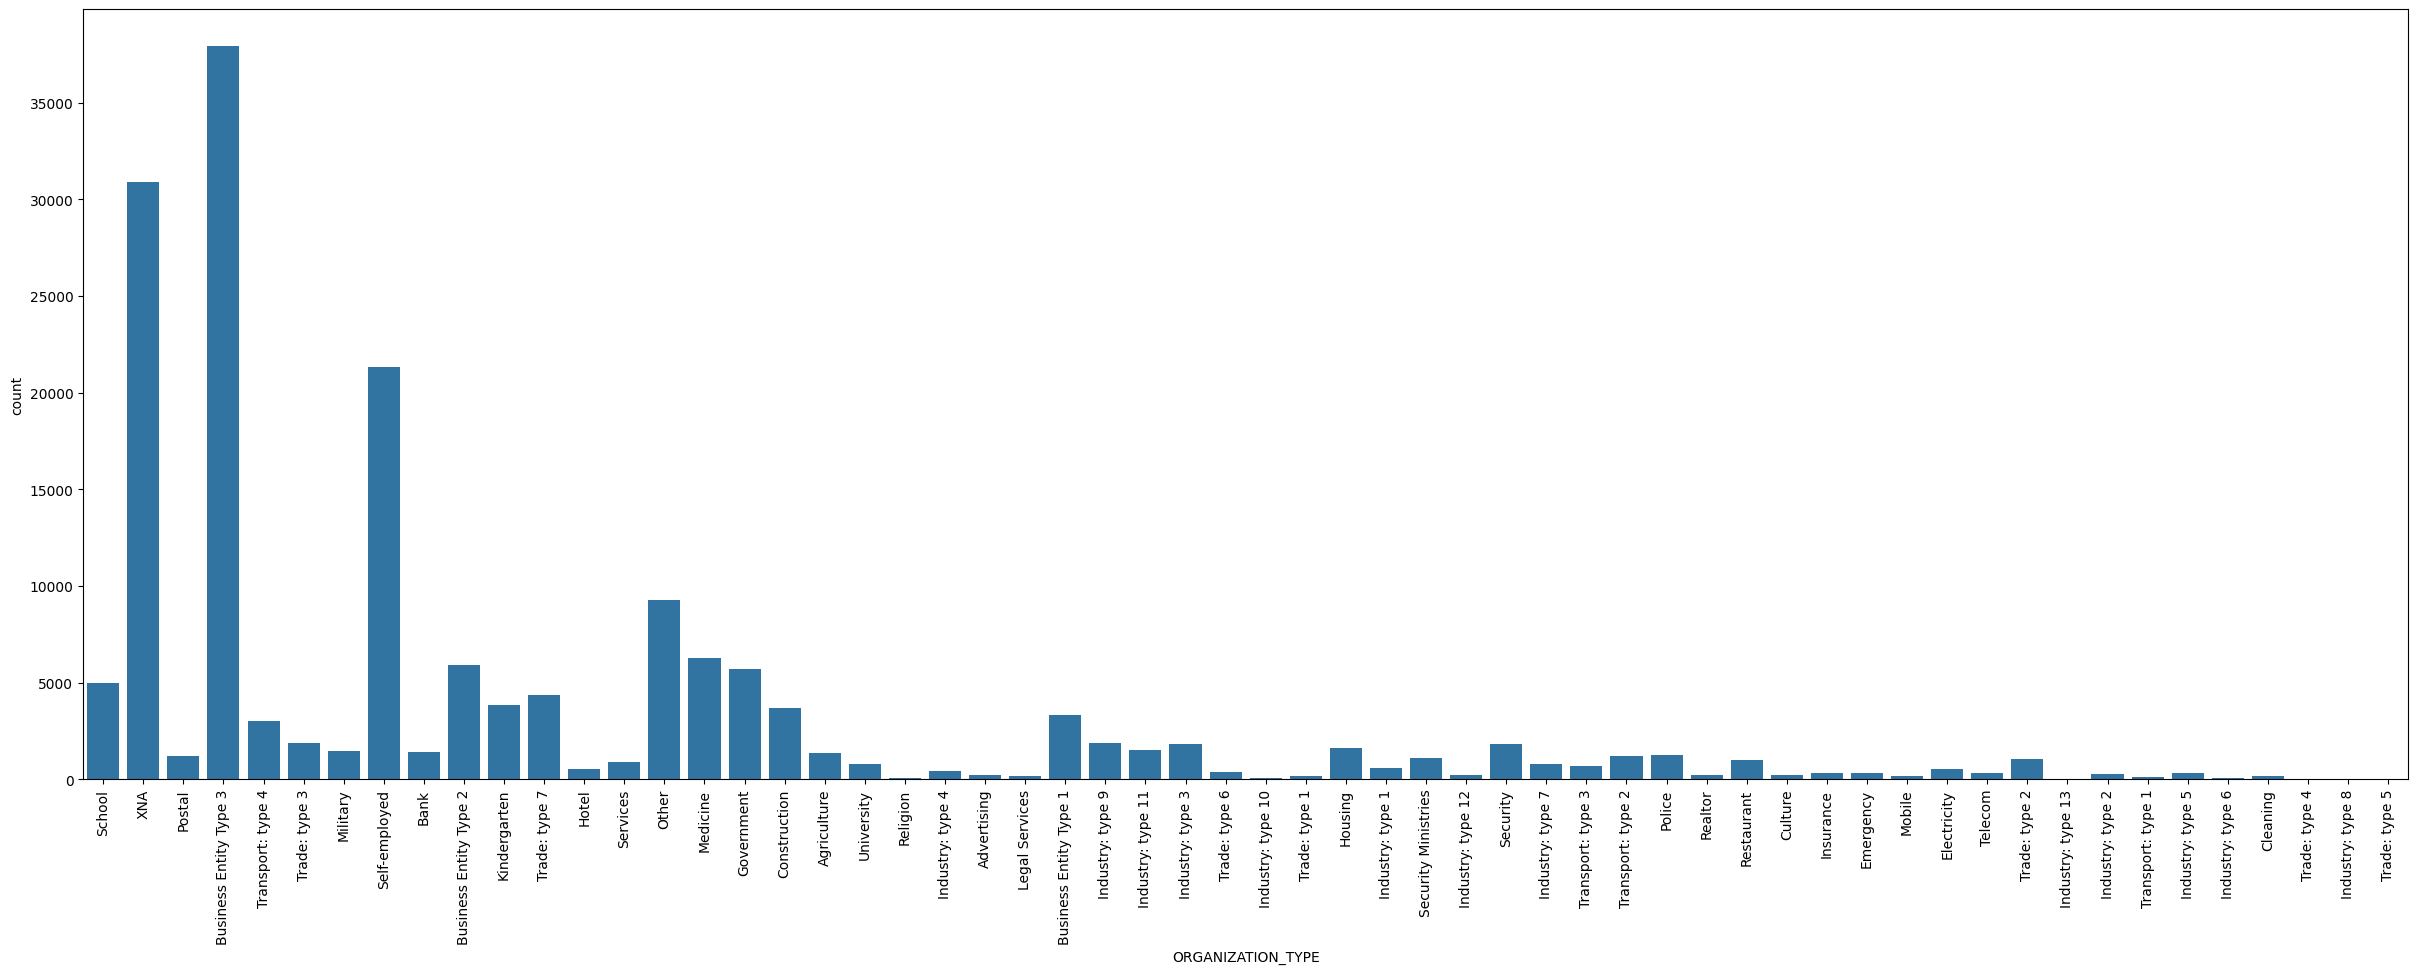

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

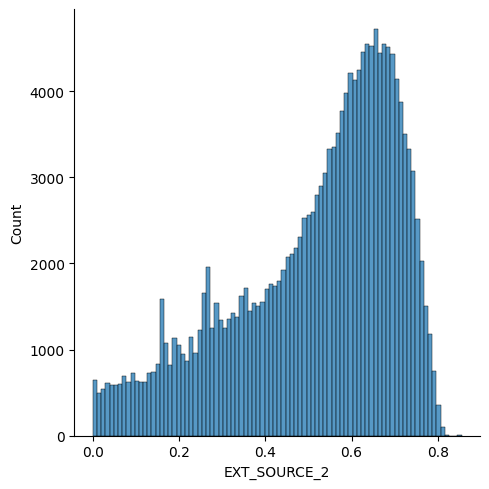

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL column

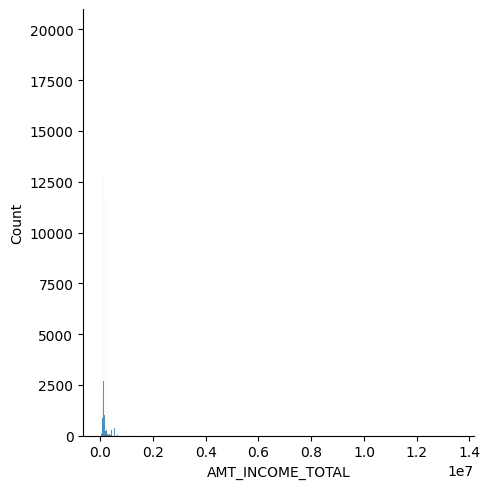

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

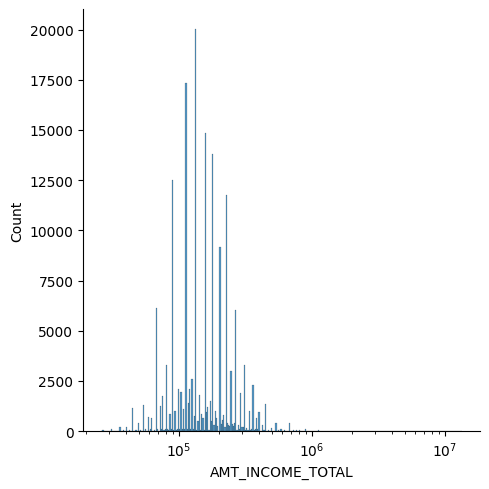

In [ ]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

,count
AMT_INCOME_TOTAL,
135000.0,19969
112500.0,17320
157500.0,14772
180000.0,13791
90000.0,12481
225000.0,11573
202500.0,9128
67500.0,6130
270000.0,6006


It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE column

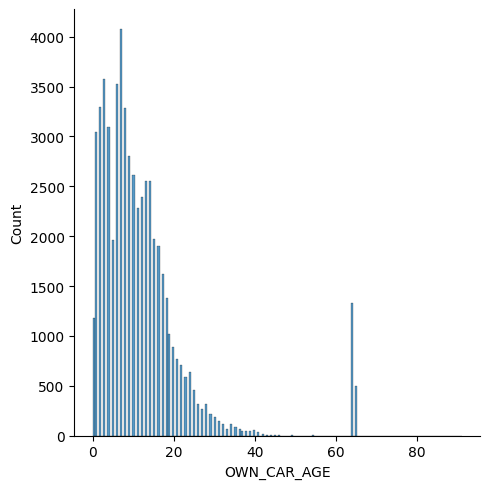

In [ ]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [ ]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,0,112500.0,0.372591,NaN,School,0
1,0,225000.0,0.449567,NaN,XNA,0
2,0,54000.0,0.569503,NaN,Postal,0
3,0,67500.0,0.105235,NaN,XNA,0
4,0,157500.0,0.202490,NaN,Business Entity Type 3,1


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [ ]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,TARGET
0,0,112500.0,0.372591,NaN,4991,0
1,0,225000.0,0.449567,NaN,30898,0
2,0,54000.0,0.569503,NaN,1185,0
3,0,67500.0,0.105235,NaN,30898,0
4,0,157500.0,0.202490,NaN,37943,1


### EXT_SOURCE_2 column
Fill missing values in `EXT_SOURCE_2`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [ ]:
#My change
train=train.dropna()

In [ ]:
train.shape

(58107, 6)

In [ ]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True) # Use average of train data to fill test data

train.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,0
OWN_CAR_AGE,112992
ORGANIZATION_TYPE,0
TARGET,0


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [ ]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [ ]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

array([ 0.,  2.,  1., nan,  3.,  4.,  5.])

In [ ]:
#My change
train=train.dropna()

In [ ]:
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,ORGANIZATION_TYPE,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,112500.0,0.372591,4991,0,False,False,False,False,False,False
1,0,225000.0,0.449567,30898,0,False,False,False,False,False,False
2,0,54000.0,0.569503,1185,0,False,False,False,False,False,False
3,0,67500.0,0.105235,30898,0,False,False,False,False,False,False
4,0,157500.0,0.202490,37943,1,False,False,False,False,False,False


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [41]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [ ]:
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [38]:
# Standardization
#sc = StandardScaler()
#sc.fit(X)
#X_std = sc.transform(X)
#X_test_std = sc.transform(X_test)

###5.2.1 Splitting our data (Mine)


In [68]:
X = train[feature_cols].copy()
y = train[target].copy()

X_test = test[feature_cols].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [ ]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.2, stratify=y, random_state=42)

Now, let's create models with logistic regression and random forest.

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

Train Score: 0.6668849182475332
Valid Score: 0.6687931107131446


In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

Train Score: 0.8155718610210831
Valid Score: 0.66844303764749


###5.3.1 Model building (Mine)


In [45]:
from sklearn.metrics import roc_auc_score
import time

def evaluate_model(model, X_train, y_train, X_val, y_val, name):
    start = time.time()

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict_proba(X_train)[:, 1]
    val_pred = model.predict_proba(X_val)[:, 1]

    train_auc = roc_auc_score(y_train, train_pred)
    val_auc = roc_auc_score(y_val, val_pred)

    elapsed = time.time() - start

    print(f"{name}")
    print(f"Train ROC-AUC: {train_auc:.5f}")
    print(f"Val ROC-AUC:   {val_auc:.5f}")
    print(f"Time:          {elapsed:.1f}s")

    return {
        "model": name,
        "train_auc": train_auc,
        "val_auc": val_auc,
        "time": elapsed,
        "model_object": model,
        "val_pred": val_pred
    }

###CatBoost specific stuff

In [69]:
cat_indices = [
    X_train.columns.get_loc(col)
    for col in cat_cols
]

In [52]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.3 MB/s eta 0:00:00


In [70]:
from catboost import CatBoostClassifier

cat_configs = [
    {
        "name": "CatBoost_1",
        "iterations": 1000,
        "depth": 6,
        "learning_rate": 0.05,
        "l2_leaf_reg": 3
    },
    {
        "name": "CatBoost_2",
        "iterations": 1500,
        "depth": 7,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5
    },
    {
        "name": "CatBoost_3",
        "iterations": 1500,
        "depth": 8,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5
    },
    {
        "name": "CatBoost_4_weighted",
        "iterations": 1500,
        "depth": 7,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5,
        "auto_class_weights": "Balanced"
    }
]

In [71]:
cat_results = []

for cfg in cat_configs:

    params = cfg.copy()
    name = params.pop("name")

    model = CatBoostClassifier(
        **params,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False
    )

    start = time.time()

    model.fit(
        X_train,
        y_train,
        cat_features=cat_indices,
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        verbose=False
    )

    train_pred = model.predict_proba(X_train)[:, 1]
    val_pred = model.predict_proba(X_val)[:, 1]

    result = {
        "model": name,
        "train_auc": roc_auc_score(y_train, train_pred),
        "val_auc": roc_auc_score(y_val, val_pred),
        "time": time.time() - start,
        "model_object": model,
        "val_pred": val_pred
    }

    cat_results.append(result)

    print(
        f"{name}: "
        f"Train={result['train_auc']:.5f}, "
        f"Val={result['val_auc']:.5f}"
    )

CatBoost_1: Train=0.81151, Val=0.75731
CatBoost_2: Train=0.82142, Val=0.75700
CatBoost_3: Train=0.81919, Val=0.75578
CatBoost_4_weighted: Train=0.82825, Val=0.75552


The first catboost model showed the highest accuracy in terms of validation set.

###Lightgbm related work

In [28]:
pip install lightgbm

In [29]:
import lightgbm as lgb

X_lgb = X.copy()

for col in cat_cols:
    X_lgb[col] = X_lgb[col].astype("category")

X_train_lgb, X_val_lgb, y_train_lgb, y_val_lgb = train_test_split(
    X_lgb,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [31]:


lgb_configs = [
    {
        "name": "LightGBM_1",
        "num_leaves": 31,
        "max_depth": -1,
        "learning_rate": 0.03,
        "min_child_samples": 20
    },
    {
        "name": "LightGBM_2",
        "num_leaves": 63,
        "max_depth": -1,
        "learning_rate": 0.03,
        "min_child_samples": 20
    },
    {
        "name": "LightGBM_3",
        "num_leaves": 31,
        "max_depth": 8,
        "learning_rate": 0.03,
        "min_child_samples": 50
    }
]

In [32]:
lgb_results = []

for cfg in lgb_configs:

    params = cfg.copy()
    name = params.pop("name")

    model = lgb.LGBMClassifier(
        n_estimators=1500,
        colsample_bytree=0.8,
        subsample=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **params
    )

    start = time.time()

    model.fit(
        X_train_lgb,
        y_train_lgb,
        categorical_feature=cat_cols,
        eval_set=[(X_val_lgb, y_val_lgb)],
        callbacks=[
            lgb.early_stopping(100, verbose=False)
        ]
    )

    train_pred = model.predict_proba(X_train_lgb)[:, 1]
    val_pred = model.predict_proba(X_val_lgb)[:, 1]

    result = {
        "model": name,
        "train_auc": roc_auc_score(y_train_lgb, train_pred),
        "val_auc": roc_auc_score(y_val_lgb, val_pred),
        "time": time.time() - start,
        "model_object": model,
        "val_pred": val_pred
    }

    lgb_results.append(result)

    print(
        f"{name}: "
        f"Train={result['train_auc']:.5f}, "
        f"Val={result['val_auc']:.5f}"
    )

LightGBM_1: Train=0.83714, Val=0.74590
LightGBM_2: Train=0.87685, Val=0.74453
LightGBM_3: Train=0.83137, Val=0.74588


###XGBoost experiments

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            cat_cols
        )
    ],
    remainder="passthrough"
)

X_train_xgb = preprocessor.fit_transform(X_train)
X_val_xgb = preprocessor.transform(X_val)

In [47]:
neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
scale_pos_weight = neg_count / pos_count

In [48]:
from xgboost import XGBClassifier

xgb_configs = [
    {
        "name": "XGBoost_1",
        "max_depth": 4,
        "min_child_weight": 5
    },
    {
        "name": "XGBoost_2",
        "max_depth": 6,
        "min_child_weight": 5
    },
    {
        "name": "XGBoost_3",
        "max_depth": 6,
        "min_child_weight": 10
    },
    {
        "name": "XGBoost_4_weighted",
        "max_depth": 6,
        "min_child_weight": 5,
        "scale_pos_weight": scale_pos_weight
    }
]

In [49]:
xgb_results = []

for cfg in xgb_configs:

    params = cfg.copy()
    name = params.pop("name")

    model = XGBClassifier(
        n_estimators=1500,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        random_state=42,
        n_jobs=-1,
        **params
    )

    start = time.time()

    model.fit(
        X_train_xgb,
        y_train,
        eval_set=[(X_val_xgb, y_val)],
        verbose=False
    )

    train_pred = model.predict_proba(X_train_xgb)[:, 1]
    val_pred = model.predict_proba(X_val_xgb)[:, 1]

    result = {
        "model": name,
        "train_auc": roc_auc_score(y_train, train_pred),
        "val_auc": roc_auc_score(y_val, val_pred),
        "time": time.time() - start,
        "model_object": model,
        "val_pred": val_pred
    }

    xgb_results.append(result)

    print(
        f"{name}: "
        f"Train={result['train_auc']:.5f}, "
        f"Val={result['val_auc']:.5f}"
    )

XGBoost_1: Train=0.81827, Val=0.74742
XGBoost_2: Train=0.89849, Val=0.74354
XGBoost_3: Train=0.88409, Val=0.74354
XGBoost_4_weighted: Train=0.92391, Val=0.73644


We find that random forest results with higher validation score.

### 5.4 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [ ]:
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2

print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

Train Score: 0.765083267129124
Valid Score: 0.6713382811742957


We find that in this case, ensemble leaning does not contribute to improved score. So, **we will use the random forest model as the final model to make predictions on the test data**.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [ ]:
# Make predictions for the test data
# Change model name if needed
pred = rf.predict_proba(X_test_std)[:, 1]

###6.1.1 My prediction

In [72]:
model=cat_results[0]["model_object"]
model

CatBoostClassifier(depth=6, eval_metric='AUC', iterations=1000, l2_leaf_reg=3, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [73]:
model.fit(X,y,cat_features=cat_indices)

CatBoostClassifier(depth=6, eval_metric='AUC', iterations=1000, l2_leaf_reg=3, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [74]:
pred = model.predict_proba(X_test)[:, 1]

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [75]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.028365
1,171203,0.184035
2,171204,0.141077
3,171205,0.108156
4,171206,0.163444
...,...,...
61495,232697,0.090709
61496,232698,0.027824
61497,232699,0.059680
61498,232700,0.235922


In [76]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [77]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: /content/drive/MyDrive/Competition/tutorial.zip


In [78]:
from google.colab import files

files.download("./output/submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>